In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_DIR = Path('../data')
SUSCEPTIBILITY_DATA = DATA_DIR / 'himalayan_landslide_v1_dataset.csv'
LITHOLOGY_GEOJSON = DATA_DIR / 'himalayan_lithology.geojson'

print('Working directory:', Path.cwd())
print('Data directory exists:', DATA_DIR.exists())
print('Susceptibility dataset exists:', SUSCEPTIBILITY_DATA.exists())
print('Lithology file exists:', LITHOLOGY_GEOJSON.exists())

Working directory: c:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\notebooks
Data directory exists: True
Susceptibility dataset exists: True
Lithology file exists: True


In [2]:
if not SUSCEPTIBILITY_DATA.exists():
    raise FileNotFoundError(
        f'Cannot find {SUSCEPTIBILITY_DATA}. Make sure this notebook is in the notebooks/ folder.'
    )

df = pd.read_csv(SUSCEPTIBILITY_DATA)
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
display(df.head())

Shape: (23018, 7)
Columns: ['LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE', 'RAINFALL', 'LANDCOVER_CODE', 'LANDSLIDE']


,LATITUDE,LONGITUDE,ELEVATION,SLOPE,RAINFALL,LANDCOVER_CODE,LANDSLIDE
0,32.919059,75.877266,3479,39.549946,3.476299,60,1
1,32.918856,75.876429,3453,32.201588,3.476299,30,1
2,32.917961,75.876663,3409,25.235184,3.476299,60,1
3,32.916468,75.879924,3265,48.509022,3.476299,30,1
4,32.910277,75.880926,3162,52.606400,3.476299,30,1


In [3]:
print('DATA TYPES')
display(df.dtypes.to_frame('dtype'))

print('MISSING VALUES')
display(df.isna().sum().to_frame('missing_count'))

print('DUPLICATE ROWS:', int(df.duplicated().sum()))

required = {'LATITUDE', 'LONGITUDE', 'LANDSLIDE'}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f'Missing expected columns: {sorted(missing_required)}')

print('Target values:')
print(df['LANDSLIDE'].value_counts(dropna=False).sort_index())
print('Target proportions:')
print(df['LANDSLIDE'].value_counts(normalize=True, dropna=False).sort_index().round(4))

DATA TYPES


,dtype
LATITUDE,float64
LONGITUDE,float64
ELEVATION,int64
SLOPE,float64
RAINFALL,float64
LANDCOVER_CODE,int64
LANDSLIDE,int64


MISSING VALUES


,missing_count
LATITUDE,0
LONGITUDE,0
ELEVATION,0
SLOPE,0
RAINFALL,0
LANDCOVER_CODE,0
LANDSLIDE,0


DUPLICATE ROWS: 705
Target values:
LANDSLIDE
0    11509
1    11509
Name: count, dtype: int64
Target proportions:
LANDSLIDE
0    0.5
1    0.5
Name: proportion, dtype: float64


In [4]:
print('Coordinate summary:')
display(df[['LATITUDE', 'LONGITUDE']].describe().T)

invalid_coordinates = df[
    df['LATITUDE'].isna()
    | df['LONGITUDE'].isna()
    | ~df['LATITUDE'].between(-90, 90)
    | ~df['LONGITUDE'].between(-180, 180)
]
print('Rows with invalid/missing coordinates:', len(invalid_coordinates))

numeric_cols = df.select_dtypes(include='number').columns.tolist()
display(df[numeric_cols].describe().T)

Coordinate summary:


,count,mean,std,min,25%,50%,75%,max
LATITUDE,23018.0,30.976283,0.996775,28.727639,30.202037,30.885260,31.778166,33.166375
LONGITUDE,23018.0,78.075900,1.224284,75.609110,77.089923,77.980449,79.066273,81.010408


Rows with invalid/missing coordinates: 0


,count,mean,std,min,25%,50%,75%,max
LATITUDE,23018.0,30.976283,0.996775,28.727639,30.202037,30.885260,31.778166,33.166375
LONGITUDE,23018.0,78.075900,1.224284,75.609110,77.089923,77.980449,79.066273,81.010408
ELEVATION,23018.0,2061.784690,1478.075061,187.000000,992.000000,1565.000000,2684.750000,6831.000000
SLOPE,23018.0,27.851241,13.037896,0.000000,19.389796,28.656198,36.622769,75.853127
RAINFALL,23018.0,3.775170,1.166837,0.625721,3.205539,3.941704,4.368923,8.566375
LANDCOVER_CODE,23018.0,28.625424,22.875478,10.000000,10.000000,30.000000,40.000000,100.000000
LANDSLIDE,23018.0,0.500000,0.500011,0.000000,0.000000,0.500000,1.000000,1.000000


In [5]:
coordinate_counts = (
    df.groupby(['LATITUDE', 'LONGITUDE'], dropna=False)
      .agg(rows=('LANDSLIDE', 'size'), unique_labels=('LANDSLIDE', 'nunique'))
      .reset_index()
)

print('Unique coordinates:', len(coordinate_counts))
print('Coordinates represented by multiple rows:', int((coordinate_counts['rows'] > 1).sum()))
print('Coordinates with conflicting target labels:', int((coordinate_counts['unique_labels'] > 1).sum()))

conflicting_coordinates = coordinate_counts[coordinate_counts['unique_labels'] > 1]
display(conflicting_coordinates.head(20))

Unique coordinates: 22313
Coordinates represented by multiple rows: 407
Coordinates with conflicting target labels: 0


,LATITUDE,LONGITUDE,rows,unique_labels


In [6]:
expected_features = [
    'LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE',
    'RAINFALL', 'LANDCOVER_CODE'
]
print('Expected feature columns available:')
for col in expected_features:
    print(f'{col}: {col in df.columns}')

if 'LANDSLIDE' in df.columns:
    print('Target column available: True')

print('Unique land-cover codes:', df['LANDCOVER_CODE'].nunique() if 'LANDCOVER_CODE' in df else 'not available')

Expected feature columns available:
LATITUDE: True
LONGITUDE: True
ELEVATION: True
SLOPE: True
RAINFALL: True
LANDCOVER_CODE: True
Target column available: True
Unique land-cover codes: 10


In [7]:

import pandas as pd
from pathlib import Path

# Load original dataset without modifying it
path = Path("../data/himalayan_landslide_v1_dataset.csv")
df = pd.read_csv(path)

print("1. DATASET SHAPE")
print(df.shape)

print("\n2. TARGET DISTRIBUTION")
print(df["LANDSLIDE"].value_counts(dropna=False))
print("\nTarget percentages:")
print((df["LANDSLIDE"].value_counts(normalize=True) * 100).round(2))

print("\n3. MISSING VALUES")
print(df.isnull().sum())

print("\n4. DUPLICATE ROWS")
print("Exact duplicate rows:", df.duplicated().sum())

print("\n5. UNIQUE COORDINATES")
unique_coords = df[["LATITUDE", "LONGITUDE"]].drop_duplicates()
print("Unique coordinate pairs:", len(unique_coords))
print("Duplicate coordinate rows:", df.duplicated(
    subset=["LATITUDE", "LONGITUDE"]
).sum())

print("\n6. CONFLICTING LABELS AT IDENTICAL COORDINATES")
labels_per_location = df.groupby(
    ["LATITUDE", "LONGITUDE"]
)["LANDSLIDE"].nunique()

conflicts = labels_per_location[labels_per_location > 1]
print("Locations with both labels:", len(conflicts))

if len(conflicts) > 0:
    display(conflicts.head(10))

print("\n7. COORDINATE RANGES")
display(df[["LATITUDE", "LONGITUDE"]].agg(["min", "max"]))

print("\n8. FEATURE SUMMARY")
display(df[
    ["ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"]
].describe().T)


1. DATASET SHAPE
(23018, 7)

2. TARGET DISTRIBUTION
LANDSLIDE
1    11509
0    11509
Name: count, dtype: int64

Target percentages:
LANDSLIDE
1    50.0
0    50.0
Name: proportion, dtype: float64

3. MISSING VALUES
LATITUDE          0
LONGITUDE         0
ELEVATION         0
SLOPE             0
RAINFALL          0
LANDCOVER_CODE    0
LANDSLIDE         0
dtype: int64

4. DUPLICATE ROWS
Exact duplicate rows: 705

5. UNIQUE COORDINATES
Unique coordinate pairs: 22313
Duplicate coordinate rows: 705

6. CONFLICTING LABELS AT IDENTICAL COORDINATES
Locations with both labels: 0

7. COORDINATE RANGES


,LATITUDE,LONGITUDE
min,28.727639,75.609110
max,33.166375,81.010408



8. FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
ELEVATION,23018.0,2061.784690,1478.075061,187.000000,992.000000,1565.000000,2684.750000,6831.000000
SLOPE,23018.0,27.851241,13.037896,0.000000,19.389796,28.656198,36.622769,75.853127
RAINFALL,23018.0,3.775170,1.166837,0.625721,3.205539,3.941704,4.368923,8.566375
LANDCOVER_CODE,23018.0,28.625424,22.875478,10.000000,10.000000,30.000000,40.000000,100.000000


In [8]:

import numpy as np
from sklearn.neighbors import BallTree

# Convert coordinates to radians for geographic distance calculations
positive = df[df["LANDSLIDE"] == 1][["LATITUDE", "LONGITUDE"]].to_numpy()
negative = df[df["LANDSLIDE"] == 0][["LATITUDE", "LONGITUDE"]].to_numpy()

positive_rad = np.radians(positive)
negative_rad = np.radians(negative)

# Find the nearest positive point for each negative point
tree = BallTree(positive_rad, metric="haversine")
distances, _ = tree.query(negative_rad, k=1)

# Convert radians to kilometres
nearest_km = distances[:, 0] * 6371.0088

print("Nearest positive-to-negative distance (km)")
print("Minimum:", round(nearest_km.min(), 3))
print("Median:", round(np.median(nearest_km), 3))
print("Mean:", round(nearest_km.mean(), 3))
print("Maximum:", round(nearest_km.max(), 3))

for radius in [1, 2, 5, 10]:
    count = np.sum(nearest_km < radius)
    print(f"Negative points within {radius} km of a positive: {count}")


Nearest positive-to-negative distance (km)
Minimum: 0.992
Median: 6.363
Mean: 10.938
Maximum: 63.079
Negative points within 1 km of a positive: 9
Negative points within 2 km of a positive: 1871
Negative points within 5 km of a positive: 5036
Negative points within 10 km of a positive: 7162


In [9]:

from sklearn.neighbors import BallTree
import numpy as np

positive_df = df[df["LANDSLIDE"] == 1].copy()
positive_coords = np.radians(
    positive_df[["LATITUDE", "LONGITUDE"]].to_numpy()
)

tree = BallTree(positive_coords, metric="haversine")

# k=2: first neighbor is the point itself; second is nearest other positive
distances, _ = tree.query(positive_coords, k=2)
nearest_positive_km = distances[:, 1] * 6371.0088

print("Nearest other positive point (km)")
print("Minimum:", round(nearest_positive_km.min(), 3))
print("Median:", round(np.median(nearest_positive_km), 3))
print("Mean:", round(nearest_positive_km.mean(), 3))

for radius in [1, 2, 5, 10]:
    count = np.sum(nearest_positive_km < radius)
    print(
        f"Positive points with another positive within {radius} km:",
        count,
        f"({count / len(positive_df) * 100:.1f}%)"
    )


Nearest other positive point (km)
Minimum: 0.0
Median: 0.217
Mean: 0.457
Positive points with another positive within 1 km: 10193 (88.6%)
Positive points with another positive within 2 km: 11142 (96.8%)
Positive points with another positive within 5 km: 11477 (99.7%)
Positive points with another positive within 10 km: 11500 (99.9%)


In [10]:

positive_df = df[df["LANDSLIDE"] == 1].copy()

unique_positive_locations = positive_df[
    ["LATITUDE", "LONGITUDE"]
].drop_duplicates()

print("Positive samples:", len(positive_df))
print("Unique positive coordinates:", len(unique_positive_locations))
print(
    "Positive samples sharing coordinates:",
    len(positive_df) - len(unique_positive_locations)
)

print("\nMost frequently repeated positive coordinates:")
display(
    positive_df.groupby(["LATITUDE", "LONGITUDE"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("sample_count")
    .reset_index()
)


Positive samples: 11509
Unique positive coordinates: 10804
Positive samples sharing coordinates: 705

Most frequently repeated positive coordinates:


,LATITUDE,LONGITUDE,sample_count
0,30.7175,78.3508,19
1,32.4500,76.5200,15
2,32.4300,75.9600,12
3,32.4200,75.9600,9
4,32.6400,76.0800,9
5,32.4800,76.2900,8
6,32.4300,76.5300,8
7,32.4500,76.5100,7
8,32.6200,76.0000,7
9,32.7000,76.0500,7


In [11]:

positive_df = df[df["LANDSLIDE"] == 1].copy()

features_to_check = [
    "ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"
]

repeated = positive_df[
    positive_df.duplicated(
        subset=["LATITUDE", "LONGITUDE"], keep=False
    )
].sort_values(["LATITUDE", "LONGITUDE"])

print("Rows at repeated positive coordinates:", len(repeated))
print("\nUnique feature combinations at repeated coordinates:")
print(
    repeated.groupby(["LATITUDE", "LONGITUDE"])[features_to_check]
    .nunique()
    .describe()
)

print("\nExample repeated coordinates and their records:")
display(
    repeated.groupby(["LATITUDE", "LONGITUDE"])
    .size()
    .sort_values(ascending=False)
    .head(3)
    .rename("count")
    .reset_index()
    .merge(
        repeated,
        on=["LATITUDE", "LONGITUDE"]
    )[
        ["LATITUDE", "LONGITUDE"] + features_to_check
    ]
    .head(20)
)


Rows at repeated positive coordinates: 1112

Unique feature combinations at repeated coordinates:
       ELEVATION  SLOPE  RAINFALL  LANDCOVER_CODE
count      407.0  407.0     407.0           407.0
mean         1.0    1.0       1.0             1.0
std          0.0    0.0       0.0             0.0
min          1.0    1.0       1.0             1.0
25%          1.0    1.0       1.0             1.0
50%          1.0    1.0       1.0             1.0
75%          1.0    1.0       1.0             1.0
max          1.0    1.0       1.0             1.0

Example repeated coordinates and their records:


,LATITUDE,LONGITUDE,ELEVATION,SLOPE,RAINFALL,LANDCOVER_CODE
0,30.7175,78.3508,996,16.679499,4.924717,10
1,30.7175,78.3508,996,16.679499,4.924717,10
2,30.7175,78.3508,996,16.679499,4.924717,10
3,30.7175,78.3508,996,16.679499,4.924717,10
4,30.7175,78.3508,996,16.679499,4.924717,10
5,30.7175,78.3508,996,16.679499,4.924717,10
6,30.7175,78.3508,996,16.679499,4.924717,10
7,30.7175,78.3508,996,16.679499,4.924717,10
8,30.7175,78.3508,996,16.679499,4.924717,10
9,30.7175,78.3508,996,16.679499,4.924717,10


In [12]:

# Read-only duplicate and label-overlap audit
coord_cols = ["LATITUDE", "LONGITUDE"]
feature_cols = [
    "ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"
]

print("1. REPEATED COORDINATES BY CLASS")
for label in [0, 1]:
    subset = df[df["LANDSLIDE"] == label]
    unique_count = subset[coord_cols].drop_duplicates().shape[0]

    print(
        f"Class {label}: {len(subset)} rows, "
        f"{unique_count} unique coordinates, "
        f"{len(subset) - unique_count} extra rows"
    )

print("\n2. COORDINATES SHARED BETWEEN CLASSES")
positive_coords = set(
    map(tuple, df.loc[df["LANDSLIDE"] == 1, coord_cols].to_numpy())
)
negative_coords = set(
    map(tuple, df.loc[df["LANDSLIDE"] == 0, coord_cols].to_numpy())
)

shared = positive_coords & negative_coords
print("Coordinates appearing in both classes:", len(shared))

print("\n3. EXACT DUPLICATE ROWS")
print("Exact duplicate rows:", df.duplicated().sum())

print("\n4. LABEL COUNTS AFTER COORDINATE DEDUPLICATION")
unique_location_rows = df.drop_duplicates(subset=coord_cols, keep=False)
print("Rows with coordinates appearing exactly once:", len(unique_location_rows))
print(unique_location_rows["LANDSLIDE"].value_counts())


1. REPEATED COORDINATES BY CLASS
Class 0: 11509 rows, 11509 unique coordinates, 0 extra rows
Class 1: 11509 rows, 10804 unique coordinates, 705 extra rows

2. COORDINATES SHARED BETWEEN CLASSES


Coordinates appearing in both classes: 0

3. EXACT DUPLICATE ROWS
Exact duplicate rows: 705

4. LABEL COUNTS AFTER COORDINATE DEDUPLICATION
Rows with coordinates appearing exactly once: 21906
LANDSLIDE
0    11509
1    10397
Name: count, dtype: int64


In [13]:

# Create a clean modeling copy; do not overwrite the original dataset.
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Clean rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nClass distribution after deduplication:")
print(df_clean["LANDSLIDE"].value_counts())

print("\nRemaining exact duplicates:", df_clean.duplicated().sum())

# Confirm the original dataframe is unchanged.
print("\nOriginal dataframe rows:", len(df))


Original rows: 23018
Clean rows: 22313
Rows removed: 705

Class distribution after deduplication:
LANDSLIDE
0    11509
1    10804
Name: count, dtype: int64

Remaining exact duplicates: 0

Original dataframe rows: 23018


In [14]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Work only on the cleaned copy
model_data = df_clean.copy()

# Assign approximate 10 km geographic blocks.
# This is a grouping approximation, not an exact geodesic grid.
lat_km = model_data["LATITUDE"] * 111.0
lon_km = (
    model_data["LONGITUDE"]
    * 111.0
    * np.cos(np.radians(model_data["LATITUDE"]))
)

model_data["spatial_block"] = (
    (lat_km // 10).astype(int).astype(str)
    + "_"
    + (lon_km // 10).astype(int).astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        model_data,
        model_data["LANDSLIDE"],
        groups=model_data["spatial_block"]
    )
)

train_data = model_data.iloc[train_idx].copy()
test_data = model_data.iloc[test_idx].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\nTraining class distribution:")
print(train_data["LANDSLIDE"].value_counts())

print("\nTesting class distribution:")
print(test_data["LANDSLIDE"].value_counts())

train_blocks = set(train_data["spatial_block"])
test_blocks = set(test_data["spatial_block"])

print("\nShared spatial blocks:", len(train_blocks & test_blocks))
print("Training blocks:", len(train_blocks))
print("Testing blocks:", len(test_blocks))


Training rows: 16491
Testing rows: 5822

Training class distribution:
LANDSLIDE
0    8597
1    7894
Name: count, dtype: int64

Testing class distribution:
LANDSLIDE
0    2912
1    2910
Name: count, dtype: int64

Shared spatial blocks: 0
Training blocks: 874
Testing blocks: 292


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

features = [
    "LATITUDE",
    "LONGITUDE",
    "ELEVATION",
    "SLOPE",
    "RAINFALL",
    "LANDCOVER_CODE"
]
target = "LANDSLIDE"

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), features)
])

susceptibility_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

susceptibility_model.fit(
    train_data[features],
    train_data[target]
)

predictions = susceptibility_model.predict(test_data[features])
probabilities = susceptibility_model.predict_proba(
    test_data[features]
)[:, 1]

print("SUSCEPTIBILITY BASELINE RESULTS")
print("Accuracy:", round(accuracy_score(test_data[target], predictions), 4))
print("Precision:", round(precision_score(test_data[target], predictions), 4))
print("Recall:", round(recall_score(test_data[target], predictions), 4))
print("F1:", round(f1_score(test_data[target], predictions), 4))
print("ROC-AUC:", round(roc_auc_score(test_data[target], probabilities), 4))
print("PR-AUC:", round(average_precision_score(test_data[target], probabilities), 4))

print("\nConfusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(test_data[target], predictions))

print("\nClassification report:")
print(classification_report(test_data[target], predictions))


SUSCEPTIBILITY BASELINE RESULTS
Accuracy: 0.8315
Precision: 0.8149
Recall: 0.8577
F1: 0.8358
ROC-AUC: 0.9169
PR-AUC: 0.9067

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[2345  567]
 [ 414 2496]]

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.81      0.83      2912
           1       0.81      0.86      0.84      2910

    accuracy                           0.83      5822
   macro avg       0.83      0.83      0.83      5822
weighted avg       0.83      0.83      0.83      5822



In [16]:

import pandas as pd

rf = susceptibility_model.named_steps["classifier"]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.round(4))


,Feature,Importance
2,ELEVATION,0.3534
3,SLOPE,0.1691
0,LATITUDE,0.1329
4,RAINFALL,0.1316
1,LONGITUDE,0.1154
5,LANDCOVER_CODE,0.0976


In [17]:
terrain_features = [
    "ELEVATION",
    "SLOPE",
    "RAINFALL",
    "LANDCOVER_CODE"
]

terrain_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), terrain_features)
    ])),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

terrain_model.fit(
    train_data[terrain_features],
    train_data["LANDSLIDE"]
)

terrain_predictions = terrain_model.predict(test_data[terrain_features])
terrain_probabilities = terrain_model.predict_proba(
    test_data[terrain_features]
)[:, 1]

print("Terrain-only model results")
print("Accuracy:", round(accuracy_score(
    test_data["LANDSLIDE"], terrain_predictions
), 4))
print("Precision:", round(precision_score(
    test_data["LANDSLIDE"], terrain_predictions
), 4))
print("Recall:", round(recall_score(
    test_data["LANDSLIDE"], terrain_predictions
), 4))
print("F1-score:", round(f1_score(
    test_data["LANDSLIDE"], terrain_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    test_data["LANDSLIDE"], terrain_probabilities
), 4))
print("PR-AUC:", round(average_precision_score(
    test_data["LANDSLIDE"], terrain_probabilities
), 4))

Terrain-only model results
Accuracy: 0.7947
Precision: 0.7702
Recall: 0.8399
F1-score: 0.8036
ROC-AUC: 0.8775
PR-AUC: 0.859


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

terrain_lr_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), terrain_features)
    ])),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

terrain_lr_model.fit(
    train_data[terrain_features],
    train_data["LANDSLIDE"]
)

lr_predictions = terrain_lr_model.predict(
    test_data[terrain_features]
)
lr_probabilities = terrain_lr_model.predict_proba(
    test_data[terrain_features]
)[:, 1]

print("Terrain-only Logistic Regression")
print("Accuracy:", round(accuracy_score(
    test_data["LANDSLIDE"], lr_predictions
), 4))
print("Precision:", round(precision_score(
    test_data["LANDSLIDE"], lr_predictions
), 4))
print("Recall:", round(recall_score(
    test_data["LANDSLIDE"], lr_predictions
), 4))
print("F1-score:", round(f1_score(
    test_data["LANDSLIDE"], lr_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    test_data["LANDSLIDE"], lr_probabilities
), 4))
print("PR-AUC:", round(average_precision_score(
    test_data["LANDSLIDE"], lr_probabilities
), 4))

Terrain-only Logistic Regression
Accuracy: 0.7501
Precision: 0.731
Recall: 0.7911
F1-score: 0.7599
ROC-AUC: 0.8225
PR-AUC: 0.7956


In [19]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), terrain_features)
    ])),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(
    train_data[terrain_features],
    train_data["LANDSLIDE"]
)

gb_predictions = gb_model.predict(
    test_data[terrain_features]
)
gb_probabilities = gb_model.predict_proba(
    test_data[terrain_features]
)[:, 1]

print("Terrain-only Gradient Boosting")
print("Accuracy:", round(accuracy_score(
    test_data["LANDSLIDE"], gb_predictions
), 4))
print("Precision:", round(precision_score(
    test_data["LANDSLIDE"], gb_predictions
), 4))
print("Recall:", round(recall_score(
    test_data["LANDSLIDE"], gb_predictions
), 4))
print("F1-score:", round(f1_score(
    test_data["LANDSLIDE"], gb_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    test_data["LANDSLIDE"], gb_probabilities
), 4))
print("PR-AUC:", round(average_precision_score(
    test_data["LANDSLIDE"], gb_probabilities
), 4))

Terrain-only Gradient Boosting
Accuracy: 0.8063
Precision: 0.7767
Recall: 0.8595
F1-score: 0.816
ROC-AUC: 0.8866
PR-AUC: 0.8695


In [20]:
import pandas as pd

gb = gb_model.named_steps["classifier"]

importance = pd.DataFrame({
    "Feature": terrain_features,
    "Importance": gb.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.round(4))

,Feature,Importance
0,ELEVATION,0.5962
1,SLOPE,0.2782
3,LANDCOVER_CODE,0.0665
2,RAINFALL,0.0591


In [21]:
core_features = ["ELEVATION", "SLOPE"]

core_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), core_features)
    ])),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

core_model.fit(
    train_data[core_features],
    train_data["LANDSLIDE"]
)

core_predictions = core_model.predict(test_data[core_features])
core_probabilities = core_model.predict_proba(
    test_data[core_features]
)[:, 1]

print("Elevation + Slope model")
print("Accuracy:", round(accuracy_score(
    test_data["LANDSLIDE"], core_predictions
), 4))
print("Precision:", round(precision_score(
    test_data["LANDSLIDE"], core_predictions
), 4))
print("Recall:", round(recall_score(
    test_data["LANDSLIDE"], core_predictions
), 4))
print("F1-score:", round(f1_score(
    test_data["LANDSLIDE"], core_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    test_data["LANDSLIDE"], core_probabilities
), 4))
print("PR-AUC:", round(average_precision_score(
    test_data["LANDSLIDE"], core_probabilities
), 4))

Elevation + Slope model
Accuracy: 0.7958
Precision: 0.7508
Recall: 0.8852
F1-score: 0.8125
ROC-AUC: 0.8606
PR-AUC: 0.8179


In [22]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_data,
        train_data["LANDSLIDE"],
        groups=train_data["spatial_block"]
    )
)

val_data = train_data.iloc[val_idx].copy()
train_data = train_data.iloc[train_idx].copy()

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

print("\nValidation class distribution:")
print(val_data["LANDSLIDE"].value_counts())

Training: (13137, 8)
Validation: (3354, 8)
Test: (5822, 8)

Validation class distribution:
LANDSLIDE
0    1784
1    1570
Name: count, dtype: int64


In [23]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd

features = [
    "ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"
]

results = []
best_model = None
best_auc = -1

for n_estimators in [100, 200, 300]:
    for learning_rate in [0.03, 0.05, 0.1]:
        for max_depth in [2, 3, 4]:
            model = Pipeline([
                ("preprocessor", ColumnTransformer([
                    ("numeric", SimpleImputer(strategy="median"), features)
                ])),
                ("classifier", GradientBoostingClassifier(
                    n_estimators=n_estimators,
                    learning_rate=learning_rate,
                    max_depth=max_depth,
                    random_state=42
                ))
            ])

            model.fit(train_data[features], train_data["LANDSLIDE"])

            pred = model.predict(val_data[features])
            prob = model.predict_proba(val_data[features])[:, 1]

            auc = roc_auc_score(val_data["LANDSLIDE"], prob)

            results.append({
                "n_estimators": n_estimators,
                "learning_rate": learning_rate,
                "max_depth": max_depth,
                "Accuracy": accuracy_score(val_data["LANDSLIDE"], pred),
                "F1": f1_score(val_data["LANDSLIDE"], pred),
                "ROC_AUC": auc,
                "PR_AUC": average_precision_score(
                    val_data["LANDSLIDE"], prob
                )
            })

            if auc > best_auc:
                best_auc = auc
                best_model = model

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
)

display(results_df.head(10).round(4))

,n_estimators,learning_rate,max_depth,Accuracy,F1,ROC_AUC,PR_AUC
2,100,0.03,4,0.8304,0.8303,0.9085,0.8843
5,100,0.05,4,0.8280,0.8254,0.9072,0.8834
1,100,0.03,3,0.8247,0.8264,0.9067,0.8804
4,100,0.05,3,0.8286,0.8280,0.9064,0.8813
9,200,0.03,2,0.8241,0.8254,0.9061,0.8796
6,100,0.10,2,0.8259,0.8250,0.9061,0.8810
11,200,0.03,4,0.8256,0.8224,0.9059,0.8816
10,200,0.03,3,0.8268,0.8256,0.9058,0.8807
3,100,0.05,2,0.8247,0.8264,0.9057,0.8779
7,100,0.10,3,0.8232,0.8201,0.9057,0.8802


In [24]:
final_features = [
    "ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"
]

final_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), final_features)
    ])),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=4,
        random_state=42
    ))
])

development_data = pd.concat([train_data, val_data])

final_model.fit(
    development_data[final_features],
    development_data["LANDSLIDE"]
)

test_pred = final_model.predict(test_data[final_features])
test_prob = final_model.predict_proba(test_data[final_features])[:, 1]

print("Final tuned Gradient Boosting — Test Results")
print("Accuracy:", round(accuracy_score(
    test_data["LANDSLIDE"], test_pred
), 4))
print("Precision:", round(precision_score(
    test_data["LANDSLIDE"], test_pred
), 4))
print("Recall:", round(recall_score(
    test_data["LANDSLIDE"], test_pred
), 4))
print("F1-score:", round(f1_score(
    test_data["LANDSLIDE"], test_pred
), 4))
print("ROC-AUC:", round(roc_auc_score(
    test_data["LANDSLIDE"], test_prob
), 4))
print("PR-AUC:", round(average_precision_score(
    test_data["LANDSLIDE"], test_prob
), 4))

Final tuned Gradient Boosting — Test Results
Accuracy: 0.8073
Precision: 0.7707
Recall: 0.8746
F1-score: 0.8194
ROC-AUC: 0.8851
PR-AUC: 0.8672


In [25]:
import numpy as np
from sklearn.neighbors import BallTree

# Coordinates in radians: latitude, longitude
train_coords = np.radians(
    train_data[["LATITUDE", "LONGITUDE"]].to_numpy()
)

test_coords = np.radians(
    test_data[["LATITUDE", "LONGITUDE"]].to_numpy()
)

tree = BallTree(train_coords, metric="haversine")

distances, _ = tree.query(test_coords, k=1)

# Convert radians to kilometres
nearest_km = distances[:, 0] * 6371.0

print("Nearest training-point distance (km)")
print("Minimum:", round(nearest_km.min(), 3))
print("Median:", round(np.median(nearest_km), 3))
print("Mean:", round(nearest_km.mean(), 3))
print("Maximum:", round(nearest_km.max(), 3))

for radius in [1, 5, 10]:
    print(
        f"Test points within {radius} km of training points:",
        f"{(nearest_km < radius).sum()} "
        f"({(nearest_km < radius).mean() * 100:.2f}%)"
    )

Nearest training-point distance (km)
Minimum: 0.08
Median: 3.39
Mean: 3.684
Maximum: 60.622
Test points within 1 km of training points: 307 (5.27%)
Test points within 5 km of training points: 4558 (78.29%)
Test points within 10 km of training points: 5777 (99.23%)


In [26]:
import numpy as np
from sklearn.neighbors import BallTree

# Coordinates in radians
train_coords = np.radians(
    train_data[["LATITUDE", "LONGITUDE"]].to_numpy()
)

test_coords = np.radians(
    test_data[["LATITUDE", "LONGITUDE"]].to_numpy()
)

tree = BallTree(train_coords, metric="haversine")
distances, _ = tree.query(test_coords, k=1)

nearest_km = distances[:, 0] * 6371.0

# Retain test points at least 5 km from training points
buffer_mask = nearest_km >= 5.0

buffered_test = test_data.loc[buffer_mask].copy()

print("Original test rows:", len(test_data))
print("Buffered test rows:", len(buffered_test))
print("Removed nearby rows:", (~buffer_mask).sum())

print("\nBuffered test class distribution:")
print(buffered_test["LANDSLIDE"].value_counts())

print("\nPositive class rate:")
print(round(buffered_test["LANDSLIDE"].mean(), 4))

Original test rows: 5822
Buffered test rows: 1264
Removed nearby rows: 4558

Buffered test class distribution:
LANDSLIDE
0    802
1    462
Name: count, dtype: int64

Positive class rate:
0.3655


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

buffered_pred = final_model.predict(
    buffered_test[final_features]
)

buffered_prob = final_model.predict_proba(
    buffered_test[final_features]
)[:, 1]

y_true = buffered_test["LANDSLIDE"]

print("5 km Buffered Spatial Evaluation")
print("Accuracy:", round(accuracy_score(y_true, buffered_pred), 4))
print("Precision:", round(precision_score(y_true, buffered_pred), 4))
print("Recall:", round(recall_score(y_true, buffered_pred), 4))
print("F1-score:", round(f1_score(y_true, buffered_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, buffered_prob), 4))
print("PR-AUC:", round(average_precision_score(y_true, buffered_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, buffered_pred))

5 km Buffered Spatial Evaluation
Accuracy: 0.8259
Precision: 0.7044
Recall: 0.9026
F1-score: 0.7913
ROC-AUC: 0.9102
PR-AUC: 0.8397

Confusion Matrix:
[[627 175]
 [ 45 417]]


In [28]:
# Use the existing nearest_km distances and test_data.
buffer_mask_10km = nearest_km >= 10.0
buffered_test_10km = test_data.loc[buffer_mask_10km].copy()

print("10 km buffered test rows:", len(buffered_test_10km))
print("\nClass distribution:")
print(buffered_test_10km["LANDSLIDE"].value_counts())

if buffered_test_10km["LANDSLIDE"].nunique() == 2:
    y_true_10 = buffered_test_10km["LANDSLIDE"]
    pred_10 = final_model.predict(
        buffered_test_10km[final_features]
    )
    prob_10 = final_model.predict_proba(
        buffered_test_10km[final_features]
    )[:, 1]

    print("\n10 km Buffered Evaluation")
    print("Accuracy:", round(accuracy_score(y_true_10, pred_10), 4))
    print("Precision:", round(precision_score(y_true_10, pred_10), 4))
    print("Recall:", round(recall_score(y_true_10, pred_10), 4))
    print("F1-score:", round(f1_score(y_true_10, pred_10), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true_10, prob_10), 4))
    print("PR-AUC:", round(average_precision_score(y_true_10, prob_10), 4))
else:
    print("Cannot calculate ROC-AUC: only one class is present.")

10 km buffered test rows: 45

Class distribution:
LANDSLIDE
0    34
1    11
Name: count, dtype: int64

10 km Buffered Evaluation
Accuracy: 0.7556
Precision: 0.5
Recall: 0.8182
F1-score: 0.6207
ROC-AUC: 0.7955
PR-AUC: 0.638


In [29]:
print("Unique spatial blocks:")
print("Training:", train_data["spatial_block"].nunique())
print("Validation:", val_data["spatial_block"].nunique())
print("Test:", test_data["spatial_block"].nunique())

print("\nClass distribution by split:")
for name, data in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    print(f"\n{name}:")
    print(data["LANDSLIDE"].value_counts().sort_index())
    print("Positive rate:", round(data["LANDSLIDE"].mean(), 4))

Unique spatial blocks:
Training: 699
Validation: 175
Test: 292

Class distribution by split:

Training:
LANDSLIDE
0    6813
1    6324
Name: count, dtype: int64
Positive rate: 0.4814

Validation:
LANDSLIDE
0    1784
1    1570
Name: count, dtype: int64
Positive rate: 0.4681

Test:
LANDSLIDE
0    2912
1    2910
Name: count, dtype: int64
Positive rate: 0.4998


In [30]:
import numpy as np

for radius in [5, 10, 15, 20]:
    mask = nearest_km >= radius
    subset = test_data.loc[mask]

    print(f"\nBuffer: {radius} km")
    print("Samples:", len(subset))
    print("Positive:", int((subset["LANDSLIDE"] == 1).sum()))
    print("Negative:", int((subset["LANDSLIDE"] == 0).sum()))


Buffer: 5 km
Samples: 1264
Positive: 462
Negative: 802

Buffer: 10 km
Samples: 45
Positive: 11
Negative: 34

Buffer: 15 km
Samples: 4
Positive: 1
Negative: 3

Buffer: 20 km
Samples: 1
Positive: 1
Negative: 0


In [31]:
import pandas as pd

block_summary = (
    model_data.groupby("spatial_block")
    .agg(
        samples=("LANDSLIDE", "size"),
        positives=("LANDSLIDE", "sum"),
        latitude=("LATITUDE", "mean"),
        longitude=("LONGITUDE", "mean")
    )
    .reset_index()
)

block_summary["positive_rate"] = (
    block_summary["positives"] / block_summary["samples"]
)

print("Total blocks:", len(block_summary))
print("Blocks with both classes:")
print(
    (
        (block_summary["positives"] > 0) &
        (block_summary["positives"] < block_summary["samples"])
    ).sum()
)

print("\nBlock sample-count distribution:")
print(block_summary["samples"].describe().round(2))

print("\nLargest 10 blocks:")
display(
    block_summary.sort_values("samples", ascending=False)
    .head(10)
    .round(4)
)

Total blocks: 1166
Blocks with both classes:
587

Block sample-count distribution:
count    1166.00
mean       19.14
std        16.54
min         1.00
25%        10.00
50%        15.00
75%        22.00
max       157.00
Name: samples, dtype: float64

Largest 10 blocks:


,spatial_block,samples,positives,latitude,longitude,positive_rate
527,342_733,157,151,30.8672,76.9952,0.9618
539,342_745,136,130,30.8537,78.2437,0.9559
528,342_734,135,132,30.8679,77.0796,0.9778
436,339_739,127,120,30.5937,77.4041,0.9449
573,343_746,120,114,30.9421,78.4031,0.9500
837,353_724,113,103,31.8294,76.7951,0.9115
439,339_742,108,105,30.5808,77.7019,0.9722
347,336_759,103,95,30.2976,79.2305,0.9223
437,339_740,103,92,30.5897,77.4877,0.8932
448,339_751,103,100,30.5911,78.6522,0.9709


In [32]:
block_summary["positive_rate"] = (
    block_summary["positives"] / block_summary["samples"]
)

print("Blocks dominated by positive samples (>90%):",
      (block_summary["positive_rate"] > 0.90).sum())

print("Blocks dominated by negative samples (<10%):",
      (block_summary["positive_rate"] < 0.10).sum())

print("Blocks with 10%-90% positives:",
      (
          (block_summary["positive_rate"] >= 0.10) &
          (block_summary["positive_rate"] <= 0.90)
      ).sum())

print("\nPositive-rate distribution:")
display(block_summary["positive_rate"].describe().round(3))

Blocks dominated by positive samples (>90%): 51
Blocks dominated by negative samples (<10%): 606
Blocks with 10%-90% positives: 509

Positive-rate distribution:


count    1166.000
mean        0.280
std         0.335
min         0.000
25%         0.000
50%         0.069
75%         0.600
max         1.000
Name: positive_rate, dtype: float64

In [33]:
terrain_audit = (
    model_data.groupby("LANDSLIDE")[
        ["ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(terrain_audit)

ELEVATION                   SLOPE               RAINFALL         \
               mean  median      std   mean median    std     mean median   
LANDSLIDE                                                                   
0           2719.51  2420.0  1767.19  25.11  25.60  14.59     3.38   3.63   
1           1401.31  1327.0   611.74  30.69  30.79  10.45     4.15   4.17   

                LANDCOVER_CODE                
            std           mean median    std  
LANDSLIDE                                     
0          1.25          34.81   30.0  26.97  
1          0.91          22.34   10.0  15.29

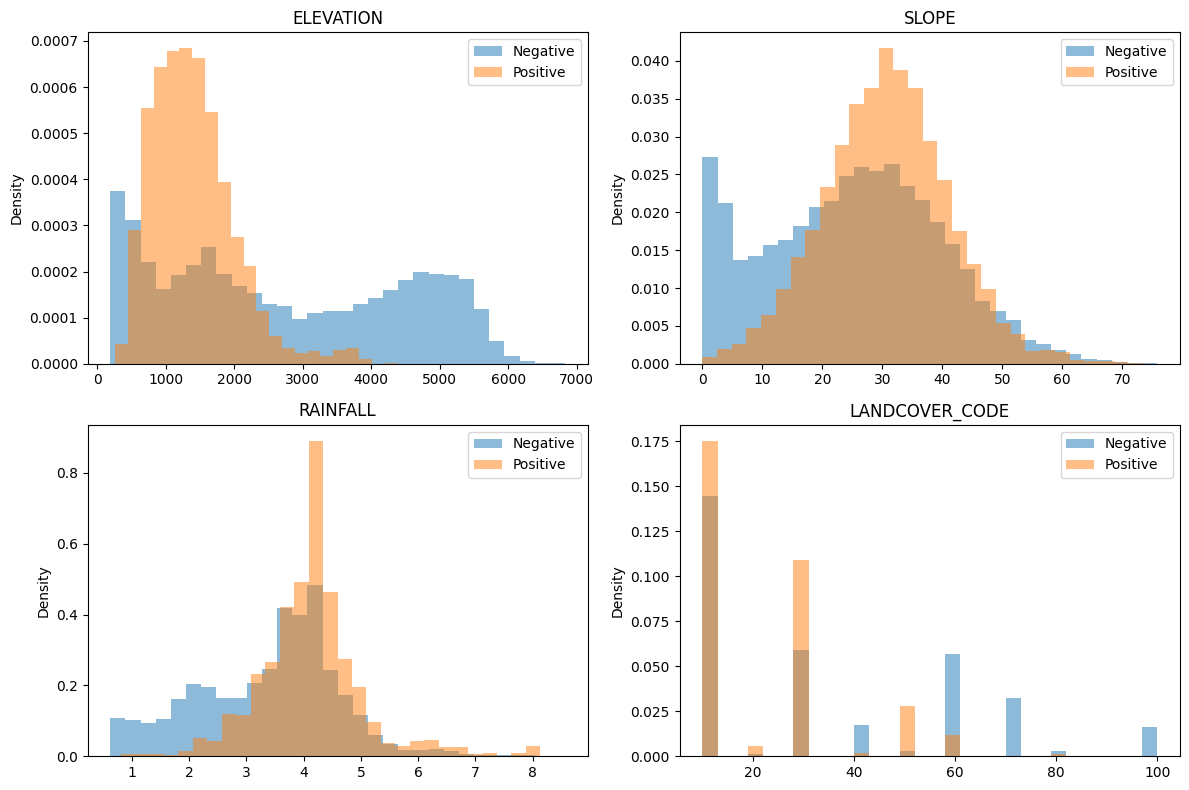

In [34]:
import matplotlib.pyplot as plt

features_to_plot = [
    "ELEVATION",
    "SLOPE",
    "RAINFALL",
    "LANDCOVER_CODE"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features_to_plot, axes.flatten()):
    for label, name in [(0, "Negative"), (1, "Positive")]:
        values = model_data.loc[
            model_data["LANDSLIDE"] == label, feature
        ]
        ax.hist(values, bins=30, alpha=0.5, density=True, label=name)

    ax.set_title(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

In [35]:
landcover_summary = (
    model_data.groupby("LANDCOVER_CODE")["LANDSLIDE"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total",
        "sum": "Landslide_Count",
        "mean": "Positive_Rate"
    })
)

landcover_summary["Negative_Count"] = (
    landcover_summary["Total"]
    - landcover_summary["Landslide_Count"]
)

display(landcover_summary.round(4))

,Total,Landslide_Count,Positive_Rate,Negative_Count
LANDCOVER_CODE,,,,
10,10676,5687,0.5327,4989
20,235,190,0.8085,45
30,5572,3535,0.6344,2037
40,660,53,0.0803,607
50,1001,903,0.9021,98
60,2347,385,0.1640,1962
70,1114,1,0.0009,1113
80,134,39,0.2910,95
90,3,0,0.0000,3


In [36]:
from pathlib import Path

for path in [
    Path("../data"),
    Path("data")
]:
    if path.exists():
        print(f"\nFiles in {path.resolve()}:")
        for file in path.iterdir():
            if file.is_file() and any(
                word in file.name.lower()
                for word in ["landcover", "lulc", "legend", "mapping", "class"]
            ):
                print(file.name)


Files in C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\data:


In [37]:
from pathlib import Path

data_dir = Path("../data")

for file in sorted(data_dir.iterdir()):
    if file.is_file():
        print(file.name)

background_locations.csv
background_locations_v2.csv
himalayan_event_rainfall.csv
himalayan_landslide_v1_dataset.csv
himalayan_lithology.geojson
himalayan_temporal_dataset.csv
himalayan_temporal_dataset_v2.csv
himalayan_temporal_final_v3.csv
himalayan_temporal_final_v4.csv
himalayan_temporal_final_v5.csv
himalayan_temporal_final_v5_lithology.csv
himalayan_temporal_model_dataset_v1.csv
HMA_LS_Cat_point_v02.0.zip
last_24h_experiment_results.csv
matched_negative_temporal.csv
multi_horizon_negative_definitions.csv
multi_horizon_negative_definitions_audited.csv
multi_horizon_negative_definitions_cleaned.csv
multi_horizon_negative_definitions_v2.csv
multi_horizon_negative_features_progress.csv
multi_horizon_negative_features_v2.csv
multi_horizon_positive_definitions.csv
multi_horizon_positive_features_v2.csv
multi_horizon_positive_labeled.csv
multi_horizon_positive_temporal.csv
negative_candidate_pool_v2.csv
negative_features_v3.csv
negative_features_v3_progress.csv
negative_features_v4.csv


In [38]:
import pandas as pd

df_source = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Land-cover codes:")
print(sorted(df_source["LANDCOVER_CODE"].dropna().unique()))

print("\nData types:")
print(df_source.dtypes)

print("\nSample rows:")
display(df_source[
    ["LATITUDE", "LONGITUDE", "LANDCOVER_CODE", "LANDSLIDE"]
].head(10))

Land-cover codes:
[10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

Data types:
LATITUDE          float64
LONGITUDE         float64
ELEVATION           int64
SLOPE             float64
RAINFALL          float64
LANDCOVER_CODE      int64
LANDSLIDE           int64
dtype: object

Sample rows:


,LATITUDE,LONGITUDE,LANDCOVER_CODE,LANDSLIDE
0,32.919059,75.877266,60,1
1,32.918856,75.876429,30,1
2,32.917961,75.876663,60,1
3,32.916468,75.879924,30,1
4,32.910277,75.880926,30,1
5,32.910956,75.880876,30,1
6,32.893503,75.846912,30,1
7,32.905932,75.848834,60,1
8,32.929304,75.834047,60,1
9,32.922642,75.832825,30,1


In [39]:
import zipfile
from pathlib import Path

zip_path = Path("../data/HMA_LS_Cat_point_v02.0.zip")

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print(name)

HMA_LS_Cat_point_v02.0.cpg
HMA_LS_Cat_point_v02.0.dbf
HMA_LS_Cat_point_v02.0.prj
HMA_LS_Cat_point_v02.0.sbn
HMA_LS_Cat_point_v02.0.sbx
HMA_LS_Cat_point_v02.0.shp
HMA_LS_Cat_point_v02.0.shp.xml
HMA_LS_Cat_point_v02.0.shx
HMA_LS_Cat_point_v02.0.xml


In [40]:
import zipfile
from pathlib import Path

zip_path = Path("../data/HMA_LS_Cat_point_v02.0.zip")

with zipfile.ZipFile(zip_path, "r") as z:
    for filename in [
        "HMA_LS_Cat_point_v02.0.xml",
        "HMA_LS_Cat_point_v02.0.shp.xml"
    ]:
        print(f"\n{'=' * 20} {filename} {'=' * 20}")
        content = z.read(filename).decode("utf-8", errors="replace")
        print(content[:12000])


==================== HMA_LS_Cat_point_v02.0.xml ====================
<?xml version="1.0" encoding="UTF-8"?><!DOCTYPE GranuleMetaDataFile SYSTEM "http://ecsinfo.gsfc.nasa.gov/ECSInfo/ecsmetadata/dtds/DPL/ECS/ScienceGranuleMetadata.dtd">
<GranuleMetaDataFile>
    <DTDVersion>1.0</DTDVersion>
    <DataCenterId>NSIDC</DataCenterId>
    <GranuleURMetaData>
        <GranuleUR>SC:HMA_LS_Cat.002:271630203</GranuleUR>
        <DbID>271630203</DbID>
        <InsertTime>2023-05-23 14:28:02.952</InsertTime>
        <LastUpdate>2023-05-23 14:28:02.952</LastUpdate>
        <CollectionMetaData>
            <ShortName>HMA_LS_Cat</ShortName>
            <VersionID>002</VersionID>
        </CollectionMetaData>
        <DataFiles>
            <DataFileContainer>
                <DistributedFileName>HMA_LS_Cat_point_v02.0.shx</DistributedFileName>
                <FileSize>22508</FileSize>
                <ChecksumType>MD5</ChecksumType>
                <Checksum>dae2bf976274c3450e317dce77e463a3</Checksu

In [41]:
import zipfile
import tempfile
from pathlib import Path
import geopandas as gpd

zip_path = Path("../data/HMA_LS_Cat_point_v02.0.zip")
extract_dir = Path(tempfile.gettempdir()) / "hma_landslide_data"
extract_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

shp_path = extract_dir / "HMA_LS_Cat_point_v02.0.shp"

gdf = gpd.read_file(shp_path)

print("Columns:")
print(gdf.columns.tolist())

print("\nFirst 5 rows:")
display(gdf.head())

print("\nData types:")
print(gdf.dtypes)

Columns:
['src_name', 'src_link', 'ev_id', 'ev_date', 'ev_time', 'ev_title', 'ev_desc', 'loc_desc', 'loc_accu', 'ls_cat', 'ls_trig', 'ls_size', 'ls_setting', 'fatalities', 'injuries', 'storm_name', 'photo_link', 'comments', 'ev_imp_src', 'ev_imp_id', 'latitude', 'longitude', 'ctry_name', 'ctry_code', 'div_name', 'gaz_point', 'gaz_dist', 'sub_date', 'edit_date', 'geometry']

First 5 rows:


,src_name,src_link,ev_id,ev_date,ev_time,ev_title,ev_desc,loc_desc,loc_accu,ls_cat,...,latitude,longitude,ctry_name,ctry_code,div_name,gaz_point,gaz_dist,sub_date,edit_date,geometry
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,2008-08-01,None,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",unknown,landslide,...,32.5625,107.4500,China,CN,Shaanxi,Micang Shan,19.18,2014-04-01,2023-04-11,POINT (107.45 32.5625)
1,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,2009-07-31,None,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,unknown,landslide,...,28.8378,81.7080,Nepal,NP,Bheri,Katti,11.78,2014-04-01,2023-04-11,POINT (81.708 28.8378)
2,UPI,https://www.upi.com/Top_News/2008/11/05/China-...,873,2008-11-01,None,"Lincang City, Yunnan, Yunnan-Tibet No. 214 hig...",The report said heavy rainfall since Oct. 24 h...,"Lincang City, Yunnan, Yunnan-Tibet No. 214 hig...",10km,complex,...,23.8900,100.0845,China,CN,Yunnan,Lin-Tsang,0.27,2014-04-01,2023-04-11,POINT (100.0845 23.89)
3,BBC News,http://news.bbc.co.uk/2/hi/asia-pacific/771010...,874,2008-11-01,None,"Kunming, Yunnan",Yunnan has so far reported 40 deaths and 43 pe...,"Kunming, Yunnan",25km,complex,...,25.0967,102.6950,China,CN,Yunnan,Kunming/Wuchia Pa,14.97,2014-04-01,2023-04-11,POINT (102.695 25.0967)
4,One India,https://www.oneindia.com/2009/07/23/darjeeling...,1054,2009-07-22,None,"Gayabari, West Bengal",The disruption of popular toy train services i...,"Gayabari, West Bengal",10km,landslide,...,26.8572,88.3143,India,IN,West Bengal,Kurseong,4.60,2014-04-01,2023-04-11,POINT (88.3143 26.8572)



Data types:
src_name              object
src_link              object
ev_id                  int64
ev_date       datetime64[ms]
ev_time               object
ev_title              object
ev_desc               object
loc_desc              object
loc_accu              object
ls_cat                object
ls_trig               object
ls_size               object
ls_setting            object
fatalities             int64
injuries               int64
storm_name            object
photo_link            object
comments              object
ev_imp_src            object
ev_imp_id             object
latitude             float64
longitude            float64
ctry_name             object
ctry_code             object
div_name              object
gaz_point             object
gaz_dist             float64
sub_date      datetime64[ms]
edit_date     datetime64[ms]
geometry            geometry
dtype: object


In [42]:
import pandas as pd

background = pd.read_csv("../data/background_locations.csv")

print("Shape:", background.shape)
print("\nColumns:")
print(background.columns.tolist())

display(background.head())

if "LANDCOVER_CODE" in background.columns:
    print("\nLand-cover distribution:")
    print(background["LANDCOVER_CODE"].value_counts().sort_index())

Shape: (374, 2)

Columns:
['latitude', 'longitude']


,latitude,longitude
0,28.866500,79.568200
1,29.158500,79.146400
2,29.295586,79.540431
3,29.330000,80.100000
4,29.337636,79.483545


In [43]:
import pandas as pd

background_v2 = pd.read_csv("../data/background_locations_v2.csv")

print("Shape:", background_v2.shape)
print("\nColumns:", background_v2.columns.tolist())

display(background_v2.head())

print("\nData types:")
print(background_v2.dtypes)

Shape: (477, 2)

Columns: ['latitude', 'longitude']


,latitude,longitude
0,31.098206,76.807250
1,31.832437,77.805359
2,30.885972,79.676747
3,28.973728,79.837911
4,29.414045,80.208788



Data types:
latitude     float64
longitude    float64
dtype: object


In [44]:
from pathlib import Path

project_dir = Path("..")

for file in project_dir.rglob("*.py"):
    if any(part.startswith(".") for part in file.parts):
        continue

    try:
        content = file.read_text(encoding="utf-8", errors="ignore")
        if "LANDCOVER_CODE" in content or "LANDCOVER" in content:
            print(f"\n--- {file} ---")
            for line_no, line in enumerate(content.splitlines(), 1):
                if "LANDCOVER" in line.upper():
                    print(f"{line_no}: {line.strip()}")
    except OSError:
        pass

In [45]:
from pathlib import Path

for folder in [Path("../notebooks"), Path(".")]:
    if folder.exists():
        print(f"\nFiles in {folder.resolve()}:")
        for file in sorted(folder.glob("*.ipynb")):
            print(file.name)


Files in C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\notebooks:
01_data_analysis.ipynb
01_susceptibility_modeling.ipynb
02_event_data.ipynb
03_event_data.ipynb
04_model_training.ipynb

Files in C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\notebooks:
01_data_analysis.ipynb
01_susceptibility_modeling.ipynb
02_event_data.ipynb
03_event_data.ipynb
04_model_training.ipynb


In [46]:
import json
from pathlib import Path

for name in [
    "01_data_analysis.ipynb",
    "01_susceptibility_modeling.ipynb"
]:
    path = Path("../notebooks") / name
    notebook = json.loads(path.read_text(encoding="utf-8"))

    print(f"\n{'=' * 15} {name} {'=' * 15}")

    for i, cell in enumerate(notebook["cells"]):
        source = "".join(cell.get("source", []))
        if any(word in source.lower() for word in [
            "landcover", "land cover", "lulc", "raster", "copernicus"
        ]):
            print(f"\n--- Cell {i} ---")
            print(source[:2500])


=============== 01_data_analysis.ipynb ===============

--- Cell 7 ---
landcover_counts = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"]
)

landcover_counts.columns = [
    "Background",
    "Landslide"
]

print(landcover_counts)

--- Cell 8 ---
landcover_names = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare/sparse vegetation",
    70: "Snow/ice",
    80: "Permanent water bodies",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss/lichen"
}

landcover_counts_named = landcover_counts.copy()

landcover_counts_named.index = (
    landcover_counts_named.index.map(landcover_names)
)

print(landcover_counts_named)

--- Cell 9 ---
landcover_percent = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"],
    normalize="columns"
) * 100

landcover_percent.columns = [
    "Background (%)",
    "Landslide (%)"
]

landcover_percent.index = (
    landcover_percent.index.map(landcover_names)
)

In [47]:
import json
from pathlib import Path

path = Path("../notebooks/01_data_analysis.ipynb")
notebook = json.loads(path.read_text(encoding="utf-8"))

cell = notebook["cells"][8]
print("".join(cell.get("source", [])))

landcover_names = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare/sparse vegetation",
    70: "Snow/ice",
    80: "Permanent water bodies",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss/lichen"
}

landcover_counts_named = landcover_counts.copy()

landcover_counts_named.index = (
    landcover_counts_named.index.map(landcover_names)
)

print(landcover_counts_named)


In [48]:
import pandas as pd

development_data = pd.concat(
    [train_data, val_data],
    ignore_index=True
)

print("Development data shape:", development_data.shape)
print("Test data shape:", test_data.shape)

Development data shape: (16491, 8)
Test data shape: (5822, 8)


In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

numeric_features = ["ELEVATION", "SLOPE", "RAINFALL"]
categorical_features = ["LANDCOVER_CODE"]

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("landcover", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

categorical_gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=4,
        random_state=42
    ))
])

categorical_gb_model.fit(
    development_data[numeric_features + categorical_features],
    development_data["LANDSLIDE"]
)

cat_pred = categorical_gb_model.predict(
    test_data[numeric_features + categorical_features]
)
cat_prob = categorical_gb_model.predict_proba(
    test_data[numeric_features + categorical_features]
)[:, 1]

y_true = test_data["LANDSLIDE"]

print("Gradient Boosting with one-hot land cover")
print("Accuracy:", round(accuracy_score(y_true, cat_pred), 4))
print("Precision:", round(precision_score(y_true, cat_pred), 4))
print("Recall:", round(recall_score(y_true, cat_pred), 4))
print("F1-score:", round(f1_score(y_true, cat_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, cat_prob), 4))
print("PR-AUC:", round(average_precision_score(y_true, cat_prob), 4))

Gradient Boosting with one-hot land cover
Accuracy: 0.8087
Precision: 0.7726
Recall: 0.8746
F1-score: 0.8204
ROC-AUC: 0.885
PR-AUC: 0.8681


In [50]:
import pandas as pd

df_audit = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Dataset shape:", df_audit.shape)

print("\nClass counts:")
print(df_audit["LANDSLIDE"].value_counts().sort_index())

print("\nExact duplicate rows:", df_audit.duplicated().sum())

print("\nDuplicate coordinates:")
print(
    df_audit.duplicated(
        subset=["LATITUDE", "LONGITUDE"],
        keep=False
    ).sum()
)

print("\nRows by class and land-cover code:")
print(pd.crosstab(
    df_audit["LANDCOVER_CODE"],
    df_audit["LANDSLIDE"]
))

print("\nFeature ranges by class:")
display(
    df_audit.groupby("LANDSLIDE")[
        ["ELEVATION", "SLOPE", "RAINFALL"]
    ].agg(["min", "median", "max"]).round(2)
)

Dataset shape: (23018, 7)

Class counts:
LANDSLIDE
0    11509
1    11509
Name: count, dtype: int64

Exact duplicate rows: 705

Duplicate coordinates:
1112

Rows by class and land-cover code:
LANDSLIDE          0     1
LANDCOVER_CODE            
10              4989  6083
20                45   196
30              2037  3705
40               607    67
50                98   953
60              1962   427
70              1113     5
80                95    59
90                 3     0
100              560    14

Feature ranges by class:


ELEVATION               SLOPE               RAINFALL             
                min  median   max   min median    max      min median   max
LANDSLIDE                                                                  
0               187  2420.0  6831   0.0  25.60  75.85     0.63   3.63  8.57
1               261  1328.0  5879   0.0  30.71  73.46     0.81   4.17  8.38

In [51]:
coordinate_labels = (
    df_audit.groupby(["LATITUDE", "LONGITUDE"])["LANDSLIDE"]
    .agg(["count", "nunique", "first"])
    .reset_index()
)

duplicate_coords = coordinate_labels[
    coordinate_labels["count"] > 1
]

conflicting_coords = coordinate_labels[
    coordinate_labels["nunique"] > 1
]

print("Unique coordinates:", len(coordinate_labels))
print("Coordinates appearing multiple times:", len(duplicate_coords))
print("Coordinates with conflicting labels:", len(conflicting_coords))

print("\nRepeated coordinates — sample:")
display(duplicate_coords.head(10))

print("\nConflicting-label coordinates — sample:")
display(conflicting_coords.head(10))

Unique coordinates: 22313
Coordinates appearing multiple times: 407
Coordinates with conflicting labels: 0

Repeated coordinates — sample:


,LATITUDE,LONGITUDE,count,nunique,first
422,29.176065,80.132172,2,1,1
681,29.270031,79.550619,3,1,1
785,29.300194,79.697389,3,1,1
883,29.328300,79.650793,3,1,1
929,29.340086,79.414492,3,1,1
1054,29.374536,79.468644,2,1,1
1155,29.403914,79.384211,2,1,1
1728,29.533583,79.544833,2,1,1
2286,29.673572,80.375032,2,1,1
3002,29.825306,80.090917,4,1,1



Conflicting-label coordinates — sample:


,LATITUDE,LONGITUDE,count,nunique,first


In [52]:
df_clean = df_audit.drop_duplicates().copy()

print("Original rows:", len(df_audit))
print("Cleaned rows:", len(df_clean))

print("\nClass counts after removing exact duplicates:")
print(df_clean["LANDSLIDE"].value_counts().sort_index())

print("\nRemaining exact duplicates:", df_clean.duplicated().sum())

print(
    "\nRemaining repeated coordinates:",
    df_clean.duplicated(
        subset=["LATITUDE", "LONGITUDE"]
    ).sum()
)

Original rows: 23018
Cleaned rows: 22313

Class counts after removing exact duplicates:
LANDSLIDE
0    11509
1    10804
Name: count, dtype: int64

Remaining exact duplicates: 0

Remaining repeated coordinates: 0


In [53]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

positive = df_clean.loc[
    df_clean["LANDSLIDE"] == 1,
    ["LATITUDE", "LONGITUDE"]
].to_numpy()

# Convert coordinates to approximate kilometres
coords_km = positive.copy()
coords_km[:, 0] *= 111.0
coords_km[:, 1] *= 111.0 * np.cos(
    np.radians(positive[:, 0])
)

neighbors = NearestNeighbors(n_neighbors=2)
neighbors.fit(coords_km)

distances, _ = neighbors.kneighbors(coords_km)
nearest_km = distances[:, 1]

print("Positive samples:", len(positive))
print("Median nearest-positive distance (km):",
      round(np.median(nearest_km), 3))
print("Mean nearest-positive distance (km):",
      round(np.mean(nearest_km), 3))
print("Positive samples with another positive within 1 km (%):",
      round(np.mean(nearest_km <= 1) * 100, 2))
print("Positive samples with another positive within 5 km (%):",
      round(np.mean(nearest_km <= 5) * 100, 2))

Positive samples: 10804
Median nearest-positive distance (km): 0.272
Mean nearest-positive distance (km): 0.534
Positive samples with another positive within 1 km (%): 86.09
Positive samples with another positive within 5 km (%): 99.64


In [54]:
import numpy as np
import pandas as pd

positive_df = df_clean[df_clean["LANDSLIDE"] == 1].copy()

lat_km = positive_df["LATITUDE"] * 111.0
lon_km = (
    positive_df["LONGITUDE"]
    * 111.0
    * np.cos(np.radians(positive_df["LATITUDE"]))
)

positive_df["spatial_block"] = (
    (lat_km // 10).astype(int).astype(str)
    + "_"
    + (lon_km // 10).astype(int).astype(str)
)

block_counts = positive_df["spatial_block"].value_counts()

print("Positive samples:", len(positive_df))
print("Unique 10 km blocks:", len(block_counts))
print("Blocks containing >20 positive samples:",
      (block_counts > 20).sum())
print("Blocks containing >50 positive samples:",
      (block_counts > 50).sum())

print("\nLargest blocks:")
display(block_counts.head(10).rename("positive_samples").to_frame())

Positive samples: 10804
Unique 10 km blocks: 598
Blocks containing >20 positive samples: 185
Blocks containing >50 positive samples: 40

Largest blocks:


,positive_samples
spatial_block,
342_733,151
342_734,132
342_745,130
339_739,120
343_746,114
339_742,105
353_724,103
339_751,100
336_759,95


In [55]:
negative_df = df_clean[df_clean["LANDSLIDE"] == 0].copy()

lat_km = negative_df["LATITUDE"] * 111.0
lon_km = (
    negative_df["LONGITUDE"]
    * 111.0
    * np.cos(np.radians(negative_df["LATITUDE"]))
)

negative_df["spatial_block"] = (
    (lat_km // 10).astype(int).astype(str)
    + "_"
    + (lon_km // 10).astype(int).astype(str)
)

negative_counts = negative_df["spatial_block"].value_counts()

print("Negative samples:", len(negative_df))
print("Unique 10 km blocks:", len(negative_counts))
print("Blocks containing >20 negative samples:",
      (negative_counts > 20).sum())
print("Blocks containing >50 negative samples:",
      (negative_counts > 50).sum())

print("\nLargest negative blocks:")
display(
    negative_counts.head(10)
    .rename("negative_samples")
    .to_frame()
)

Negative samples: 11509
Unique 10 km blocks: 1155
Blocks containing >20 negative samples: 5
Blocks containing >50 negative samples: 0

Largest negative blocks:


,negative_samples
spatial_block,
340_751,23
356_736,22
347_745,21
363_722,21
333_750,21
363_725,20
344_745,20
363_726,20
336_747,20


In [56]:
df_blocks = df_clean.copy()

lat_km = df_blocks["LATITUDE"] * 111.0
lon_km = (
    df_blocks["LONGITUDE"]
    * 111.0
    * np.cos(np.radians(df_blocks["LATITUDE"]))
)

df_blocks["spatial_block"] = (
    (lat_km // 10).astype(int).astype(str)
    + "_"
    + (lon_km // 10).astype(int).astype(str)
)

block_class_counts = pd.crosstab(
    df_blocks["spatial_block"],
    df_blocks["LANDSLIDE"]
).reindex(columns=[0, 1], fill_value=0)

mixed_blocks = (
    (block_class_counts[0] > 0)
    & (block_class_counts[1] > 0)
)

print("Total occupied blocks:", len(block_class_counts))
print("Blocks with both classes:", mixed_blocks.sum())
print("Positive-only blocks:", ((block_class_counts[1] > 0) & (block_class_counts[0] == 0)).sum())
print("Negative-only blocks:", ((block_class_counts[0] > 0) & (block_class_counts[1] == 0)).sum())

Total occupied blocks: 1166
Blocks with both classes: 587
Positive-only blocks: 11
Negative-only blocks: 568


In [57]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors

df_model = df_clean.copy()

lat_km = df_model["LATITUDE"] * 111.0
lon_km = (
    df_model["LONGITUDE"]
    * 111.0
    * np.cos(np.radians(df_model["LATITUDE"]))
)

df_model["spatial_block"] = (
    (lat_km // 10).astype(int).astype(str)
    + "_"
    + (lon_km // 10).astype(int).astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_model,
        df_model["LANDSLIDE"],
        groups=df_model["spatial_block"]
    )
)

train = df_model.iloc[train_idx].copy()
test = df_model.iloc[test_idx].copy()

# Approximate coordinate distances in kilometres
def to_km(data):
    lat = data["LATITUDE"].to_numpy()
    lon = data["LONGITUDE"].to_numpy()
    return np.column_stack([
        lat * 111.0,
        lon * 111.0 * np.cos(np.radians(lat))
    ])

nn = NearestNeighbors(n_neighbors=1).fit(to_km(train))
distances, _ = nn.kneighbors(to_km(test))
test["nearest_train_km"] = distances[:, 0]

buffered_test = test[test["nearest_train_km"] >= 5]

print("Training rows:", len(train))
print("Original test rows:", len(test))
print("Test rows at least 5 km from training:", len(buffered_test))
print("\nClass counts in buffered test:")
print(buffered_test["LANDSLIDE"].value_counts().sort_index())
print("\nPositive rate in buffered test:",
      round(buffered_test["LANDSLIDE"].mean(), 3)
      if len(buffered_test) else "No rows retained")

Training rows: 16491
Original test rows: 5822
Test rows at least 5 km from training: 1026

Class counts in buffered test:
LANDSLIDE
0    608
1    418
Name: count, dtype: int64

Positive rate in buffered test: 0.407


In [58]:
for radius in [1, 5, 10, 15, 20]:
    subset = test[test["nearest_train_km"] >= radius]

    print(
        f"{radius:>2} km buffer | "
        f"Rows: {len(subset):>4} | "
        f"Negative: {(subset['LANDSLIDE'] == 0).sum():>4} | "
        f"Positive: {(subset['LANDSLIDE'] == 1).sum():>4}"
    )

 1 km buffer | Rows: 5488 | Negative: 2842 | Positive: 2646
 5 km buffer | Rows: 1026 | Negative:  608 | Positive:  418
10 km buffer | Rows:   24 | Negative:   19 | Positive:    5
15 km buffer | Rows:    1 | Negative:    0 | Positive:    1
20 km buffer | Rows:    1 | Negative:    0 | Positive:    1


In [59]:
print("Model variables available:")

for name in [
    "gb_tuned",
    "gb_model",
    "best_gb",
    "development_data",
    "train",
    "test",
    "buffered_test"
]:
    print(f"{name}: {name in globals()}")

Model variables available:
gb_tuned: False
gb_model: True
best_gb: False
development_data: True
train: True
test: True
buffered_test: True


In [60]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

# Confirm the model can predict
X_test = test[["ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"]]
y_test = test["LANDSLIDE"]

y_pred = gb_model.predict(X_test)
y_prob = gb_model.predict_proba(X_test)[:, 1]

def evaluate(y_true, y_pred, y_prob, title):
    print(f"\n{title}")
    print("Samples:", len(y_true))
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1:", round(f1_score(y_true, y_pred, zero_division=0), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
    print("PR-AUC:", round(average_precision_score(y_true, y_prob), 4))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

evaluate(y_test, y_pred, y_prob, "Full spatial test set")

# Evaluate on test points at least 5 km from any training point
buffered = test[test["nearest_train_km"] >= 5]
X_buffered = buffered[["ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"]]
y_buffered = buffered["LANDSLIDE"]

if y_buffered.nunique() == 2:
    evaluate(
        y_buffered,
        gb_model.predict(X_buffered),
        gb_model.predict_proba(X_buffered)[:, 1],
        "5 km buffered test subset"
    )
else:
    print("\n5 km buffered subset has only one class; AUC cannot be calculated.")


Full spatial test set
Samples: 5822
Accuracy: 0.8063
Precision: 0.7767
Recall: 0.8595


F1: 0.816
ROC-AUC: 0.8866
PR-AUC: 0.8695
Confusion matrix:
 [[2193  719]
 [ 409 2501]]

5 km buffered test subset
Samples: 1026
Accuracy: 0.8138
Precision: 0.7256
Recall: 0.8732
F1: 0.7926
ROC-AUC: 0.8887
PR-AUC: 0.8209
Confusion matrix:
 [[470 138]
 [ 53 365]]


In [61]:
from pathlib import Path
import json

project_dir = Path.cwd().parent
notebook_dir = project_dir / "notebooks"

keywords = [
    "himalayan_landslide_v1_dataset",
    "background_locations",
    "LANDSLIDE",
    "drop_duplicates",
    "LANDCOVER_CODE"
]

for path in notebook_dir.glob("*.ipynb"):
    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    matches = []

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if any(word.lower() in source.lower() for word in keywords):
            matches.append((i, source))

    if matches:
        print(f"\n{'=' * 70}\nFILE: {path.name}")
        for cell_number, source in matches:
            print(f"\n--- Cell {cell_number} ---")
            print(source[:2500])


FILE: 01_data_analysis.ipynb

--- Cell 0 ---
import pandas as pd

df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

--- Cell 3 ---
df.groupby("LANDSLIDE")[["ELEVATION", "SLOPE", "RAINFALL"]].agg(
    ["mean", "median", "min", "max"]
)

--- Cell 4 ---
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column="ELEVATION",
    by="LANDSLIDE"
)

plt.title("Elevation by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Elevation (m)")
plt.show()

--- Cell 5 ---
plt.figure(figsize=(8, 5))

df.boxplot(
    column="SLOPE",
    by="LANDSLIDE"
)

plt.title("Slope by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Slope (degrees)")
plt.show()

--- Cell 6 ---
plt.figure(figsize=(8, 5))

df.boxplot(
    column="RAINFALL",
    by="LANDSLIDE"
)

pl

In [62]:
from pathlib import Path
import json

project_dir = Path.cwd().parent

terms = [
    "himalayan_landslide_v1_dataset.csv",
    "background_locations",
    "LANDSLIDE",
    "sample_background",
    "negative_samples",
    "positive_samples",
    "to_csv"
]

for path in project_dir.rglob("*"):
    if (
        not path.is_file()
        or path.suffix not in [".ipynb", ".py"]
        or any(part.startswith(".") for part in path.parts)
    ):
        continue

    try:
        if path.suffix == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            cells = [
                (i, "".join(c.get("source", [])))
                for i, c in enumerate(notebook.get("cells", []))
                if c.get("cell_type") == "code"
            ]
        else:
            cells = [(0, path.read_text(encoding="utf-8"))]

        for i, source in cells:
            matched = [
                term for term in terms
                if term.lower() in source.lower()
            ]

            if matched:
                print(f"\nFILE: {path.relative_to(project_dir)}")
                print(f"CELL: {i} | MATCHES: {matched}")
                print(source[:1800])
    except Exception:
        continue


FILE: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb
CELL: 0 | MATCHES: ['himalayan_landslide_v1_dataset.csv', 'LANDSLIDE']
import pandas as pd

df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

FILE: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb
CELL: 3 | MATCHES: ['LANDSLIDE']
df.groupby("LANDSLIDE")[["ELEVATION", "SLOPE", "RAINFALL"]].agg(
    ["mean", "median", "min", "max"]
)

FILE: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb
CELL: 4 | MATCHES: ['LANDSLIDE']
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column="ELEVATION",
    by="LANDSLIDE"
)

plt.title("Elevation by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Elevation (m)")
plt.show()

FILE: checkpoints\checkpoint_20261004_170111\notebooks\0

In [63]:
from pathlib import Path
import json

project_dir = Path.cwd().parent

for path in project_dir.rglob("*"):
    if not path.is_file() or path.suffix not in [".ipynb", ".py"]:
        continue

    try:
        if path.suffix == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            cells = [
                (i, "".join(c.get("source", [])))
                for i, c in enumerate(notebook.get("cells", []))
                if c.get("cell_type") == "code"
            ]
        else:
            cells = [(0, path.read_text(encoding="utf-8"))]

        for i, source in cells:
            lines = source.splitlines()

            relevant = [
                j for j, line in enumerate(lines)
                if (
                    "himalayan_landslide_v1_dataset" in line.lower()
                    or (
                        "to_csv" in line.lower()
                        and ("landslide" in line.lower() or "dataset" in line.lower())
                    )
                )
            ]

            if relevant:
                print(f"\nFILE: {path.relative_to(project_dir)} | CELL: {i}")
                shown = set()

                for j in relevant:
                    for k in range(max(0, j - 8), min(len(lines), j + 9)):
                        if k not in shown:
                            print(f"{k + 1}: {lines[k]}")
                            shown.add(k)
    except Exception:
        continue


FILE: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb | CELL: 0
1: import pandas as pd
2: 
3: df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")
4: 
5: print("Dataset loaded successfully")
6: print("Rows:", len(df))
7: print("Columns:", len(df.columns))
8: 
9: df.head()

FILE: checkpoints\checkpoint_20261004_170111\notebooks\02_event_data.ipynb | CELL: 29
1: static_df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")
2: 
3: print("Shape:", static_df.shape)
4: print("\nColumns:")
5: print(static_df.columns.tolist())

FILE: checkpoints\checkpoint_20261004_170111\notebooks\02_event_data.ipynb | CELL: 77
24: 
25: # Shuffle the rows
26: temporal_dataset = temporal_dataset.sample(
27:     frac=1,
28:     random_state=42
29: ).reset_index(drop=True)
30: 
31: # Save
32: temporal_dataset.to_csv(
33:     "../data/himalayan_temporal_dataset.csv",
34:     index=False
35: )
36: 
37: print("Shape:", temporal_dataset.shape)
38: 
39: print("\nTarget distr

In [64]:
import json
from pathlib import Path

path = Path("../notebooks/04_model_training.ipynb")

with open(path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i in [198, 199]:
    print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
    print("".join(notebook["cells"][i]["source"]))


==================== CELL 198 ====================

import pandas as pd

v1 = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Columns:", v1.columns.tolist())
print("\nClass distribution:")
print(v1["LANDSLIDE"].value_counts())

background_v1 = v1[v1["LANDSLIDE"] == 0][
    ["LATITUDE", "LONGITUDE"]
].drop_duplicates()

positive = pd.read_csv("../data/multi_horizon_positive_definitions.csv")

v1_keys = set(zip(
    background_v1["LATITUDE"].round(5),
    background_v1["LONGITUDE"].round(5)
))
positive_keys = set(zip(
    positive["latitude"].round(5),
    positive["longitude"].round(5)
))

print("\nUnique V1 background locations:", len(background_v1))
print("Overlaps with positive locations:", len(v1_keys & positive_keys))
print("Independent candidate locations:", len(v1_keys - positive_keys))


==================== CELL 199 ====================

import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

v1 = pd.read_csv("../data/himalayan_landslid

In [65]:
from pathlib import Path

data_dir = Path("../data")

for path in sorted(data_dir.iterdir()):
    if path.is_file() and any(
        word in path.name.lower()
        for word in [
            "landslide", "background", "negative",
            "positive", "rainfall", "elevation",
            "slope", "landcover", "dem"
        ]
    ):
        print(f"{path.name}  |  {path.stat().st_size / 1024:.1f} KB")

background_locations.csv  |  6.6 KB
background_locations_v2.csv  |  17.4 KB
himalayan_event_rainfall.csv  |  47.7 KB
himalayan_landslide_v1_dataset.csv  |  1659.3 KB
matched_negative_temporal.csv  |  54.8 KB
multi_horizon_negative_definitions.csv  |  18.5 KB
multi_horizon_negative_definitions_audited.csv  |  26.2 KB
multi_horizon_negative_definitions_cleaned.csv  |  18.4 KB
multi_horizon_negative_definitions_v2.csv  |  23.5 KB
multi_horizon_negative_features_progress.csv  |  68.6 KB
multi_horizon_negative_features_v2.csv  |  68.6 KB
multi_horizon_positive_definitions.csv  |  48.5 KB
multi_horizon_positive_features_v2.csv  |  164.5 KB
multi_horizon_positive_labeled.csv  |  136.0 KB
multi_horizon_positive_temporal.csv  |  129.8 KB
negative_candidate_pool_v2.csv  |  437.8 KB
negative_features_v3.csv  |  161.8 KB
negative_features_v3_progress.csv  |  161.8 KB
negative_features_v4.csv  |  163.4 KB
negative_features_v4_progress.csv  |  163.4 KB
negative_location_definitions_v3.csv  |  75.3 K

In [66]:
import json
from pathlib import Path

notebook_dir = Path("../notebooks")

terms = [
    "himalayan_landslide_v1_dataset.csv",
    "LANDCOVER_CODE",
    '"ELEVATION"',
    '"SLOPE"',
    '"RAINFALL"',
    "background_locations.csv",
    "background_locations_v2.csv"
]

for path in sorted(notebook_dir.glob("*.ipynb")):
    notebook = json.loads(path.read_text(encoding="utf-8"))

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matched = [t for t in terms if t.lower() in source.lower()]

        if matched:
            # Show only cells that appear to construct or save data
            if any(x in source.lower() for x in [
                "to_csv", "merge(", "landcover_code", "background_locations"
            ]):
                print(f"\nFILE: {path.name} | CELL: {i} | MATCHES: {matched}")
                print(source[:1200])


FILE: 01_data_analysis.ipynb | CELL: 7 | MATCHES: ['LANDCOVER_CODE']
landcover_counts = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"]
)

landcover_counts.columns = [
    "Background",
    "Landslide"
]

print(landcover_counts)

FILE: 01_data_analysis.ipynb | CELL: 9 | MATCHES: ['LANDCOVER_CODE']
landcover_percent = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"],
    normalize="columns"
) * 100

landcover_percent.columns = [
    "Background (%)",
    "Landslide (%)"
]

landcover_percent.index = (
    landcover_percent.index.map(landcover_names)
)

print(landcover_percent.round(2))

FILE: 01_data_analysis.ipynb | CELL: 22 | MATCHES: ['LANDCOVER_CODE', '"ELEVATION"', '"SLOPE"', '"RAINFALL"']
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Features used by the model
numeric_features = [
    "ELEVATION",
    "SLO

In [67]:
from pathlib import Path
import json

for p in Path("../notebooks").glob("*.ipynb"):
    nb = json.loads(p.read_text(encoding="utf-8"))
    for i, c in enumerate(nb["cells"]):
        s = "".join(c.get("source", []))
        if "himalayan_landslide_v1_dataset.csv" in s and "to_csv" in s:
            print(p.name, "| cell", i)
            print(s[:700], "\n")

03_event_data.ipynb | cell 18
import pandas as pd
import numpy as np
from sklearn.neighbors import NearestNeighbors

positive = pd.read_csv(
    "../data/multi_horizon_positive_labeled.csv"
)

static = pd.read_csv(
    "../data/himalayan_landslide_v1_dataset.csv"
)

# Keep only the environmental features we need
static_features = static[
    [
        "LATITUDE", "LONGITUDE",
        "ELEVATION", "SLOPE", "LANDCOVER_CODE"
    ]
].drop_duplicates(subset=["LATITUDE", "LONGITUDE"])

# Find the nearest static-data coordinate for each positive event
coords_static = np.radians(
    static_features[["LATITUDE", "LONGITUDE"]].to_numpy()
)
coords_positive = np.radians(
    positive[["latitude", "longitude"]].to_numpy()
)

nn = Ne 



In [68]:
from pathlib import Path

root = Path.cwd().parent

for p in root.rglob("*"):
    if not p.is_file():
        continue

    if (
        p.name.lower() in ["readme.md", "readme.txt"]
        or p.name.lower() in ["makefile"]
    ) and ".git" not in p.parts and "checkpoints" not in p.parts:
        print(p.relative_to(root))

README.md
.venv\Lib\site-packages\debugpy\_vendored\pydevd\pydevd_attach_to_process\README.txt
.venv\Lib\site-packages\debugpy\_vendored\pydevd\pydevd_plugins\extensions\README.md
.venv\Lib\site-packages\debugpy\_vendored\pydevd\_pydevd_frame_eval\vendored\README.txt
.venv\Lib\site-packages\zmq\backend\cffi\README.md


In [69]:
from pathlib import Path

readme = Path("../README.md")

print(readme.read_text(encoding="utf-8")[:6000])

Himalayan Landslide Susceptibility Modeling
Project overview
This project explores machine-learning methods for identifying
landslide-susceptibility patterns in the Himalayan region, focusing on
Uttarakhand and nearby Himachal Pradesh. The intended product is a
mobile-friendly dashboard where a user enters a location and views an
estimated susceptibility result. Any short-term warning output is
experimental and is not an operational warning.
Current susceptibility dataset
Dataset: data/himalayan_landslide_v1_dataset.csv
Columns: - LATITUDE - LONGITUDE - ELEVATION - SLOPE -
RAINFALL - LANDCOVER_CODE - LANDSLIDE --- target label (1 =
positive sample, 0 = background sample)
Dataset audit
The original CSV contains 23,018 rows, with 11,509 samples in each
class. An audit found 705 exact duplicate rows. Removing exact duplicate
rows produced a cleaned in-memory dataset of 22,313 rows:
  Item                                                           Count
  Original rows                      

In [70]:
from pathlib import Path

readme = next(
    p for p in Path.cwd().parent.rglob("README.md")
    if ".venv" not in p.parts and "checkpoints" not in p.parts
)

print("File:", readme)
print(readme.read_text(encoding="utf-8")[:6000])

File: c:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\README.md
Himalayan Landslide Susceptibility Modeling
Project overview
This project explores machine-learning methods for identifying
landslide-susceptibility patterns in the Himalayan region, focusing on
Uttarakhand and nearby Himachal Pradesh. The intended product is a
mobile-friendly dashboard where a user enters a location and views an
estimated susceptibility result. Any short-term warning output is
experimental and is not an operational warning.
Current susceptibility dataset
Dataset: data/himalayan_landslide_v1_dataset.csv
Columns: - LATITUDE - LONGITUDE - ELEVATION - SLOPE -
RAINFALL - LANDCOVER_CODE - LANDSLIDE --- target label (1 =
positive sample, 0 = background sample)
Dataset audit
The original CSV contains 23,018 rows, with 11,509 samples in each
class. An audit found 705 exact duplicate rows. Removing exact duplicate
rows produced a cleaned in-memory dataset of 22,313 rows:
  Item     

In [71]:
from pathlib import Path

p = Path.cwd().parent / "README.md"
text = p.read_text(encoding="utf-8")

print("Characters:", len(text))
print(text[:4000] if text.strip() else "README is empty.")

Characters: 7663
Himalayan Landslide Susceptibility Modeling
Project overview
This project explores machine-learning methods for identifying
landslide-susceptibility patterns in the Himalayan region, focusing on
Uttarakhand and nearby Himachal Pradesh. The intended product is a
mobile-friendly dashboard where a user enters a location and views an
estimated susceptibility result. Any short-term warning output is
experimental and is not an operational warning.
Current susceptibility dataset
Dataset: data/himalayan_landslide_v1_dataset.csv
Columns: - LATITUDE - LONGITUDE - ELEVATION - SLOPE -
RAINFALL - LANDCOVER_CODE - LANDSLIDE --- target label (1 =
positive sample, 0 = background sample)
Dataset audit
The original CSV contains 23,018 rows, with 11,509 samples in each
class. An audit found 705 exact duplicate rows. Removing exact duplicate
rows produced a cleaned in-memory dataset of 22,313 rows:
  Item                                                           Count
  Original rows     

In [72]:
import subprocess
from pathlib import Path

root = Path.cwd().parent

result = subprocess.run(
    ["git", "log", "--oneline", "-10"],
    cwd=root,
    capture_output=True,
    text=True
)

print(result.stdout if result.returncode == 0 else result.stderr)

fatal: not a git repository (or any of the parent directories): .git



In [73]:
from pathlib import Path

data_dir = Path("../data")

for p in sorted(data_dir.iterdir()):
    if p.is_file() and p.suffix.lower() in [
        ".csv", ".geojson", ".json", ".tif",
        ".tiff", ".shp", ".zip", ".gpkg", ".pdf"
    ]:
        print(p.name)

background_locations.csv
background_locations_v2.csv
himalayan_event_rainfall.csv
himalayan_landslide_v1_dataset.csv
himalayan_lithology.geojson
himalayan_temporal_dataset.csv
himalayan_temporal_dataset_v2.csv
himalayan_temporal_final_v3.csv
himalayan_temporal_final_v4.csv
himalayan_temporal_final_v5.csv
himalayan_temporal_final_v5_lithology.csv
himalayan_temporal_model_dataset_v1.csv
HMA_LS_Cat_point_v02.0.zip
last_24h_experiment_results.csv
matched_negative_temporal.csv
multi_horizon_negative_definitions.csv
multi_horizon_negative_definitions_audited.csv
multi_horizon_negative_definitions_cleaned.csv
multi_horizon_negative_definitions_v2.csv
multi_horizon_negative_features_progress.csv
multi_horizon_negative_features_v2.csv
multi_horizon_positive_definitions.csv
multi_horizon_positive_features_v2.csv
multi_horizon_positive_labeled.csv
multi_horizon_positive_temporal.csv
negative_candidate_pool_v2.csv
negative_features_v3.csv
negative_features_v3_progress.csv
negative_features_v4.csv


In [74]:
from zipfile import ZipFile
from pathlib import Path

path = Path("../data/HMA_LS_Cat_point_v02.0.zip")

with ZipFile(path) as z:
    for name in z.namelist()[:30]:
        print(name)

HMA_LS_Cat_point_v02.0.cpg
HMA_LS_Cat_point_v02.0.dbf
HMA_LS_Cat_point_v02.0.prj
HMA_LS_Cat_point_v02.0.sbn
HMA_LS_Cat_point_v02.0.sbx
HMA_LS_Cat_point_v02.0.shp
HMA_LS_Cat_point_v02.0.shp.xml
HMA_LS_Cat_point_v02.0.shx
HMA_LS_Cat_point_v02.0.xml


In [75]:
import geopandas as gpd
from zipfile import ZipFile

path = "../data/HMA_LS_Cat_point_v02.0.zip"

with ZipFile(path) as z:
    shp = next(n for n in z.namelist() if n.endswith(".shp"))

    with z.open(shp) as f:
        print("Shapefile found:", shp)

gdf = gpd.read_file(f"zip://{path}")

print("\nRows:", len(gdf))
print("CRS:", gdf.crs)
print("\nColumns:")
print(gdf.columns.tolist())
print("\nSample records:")
display(gdf.head(3))

Shapefile found: HMA_LS_Cat_point_v02.0.shp

Rows: 2801
CRS: EPSG:4326

Columns:
['src_name', 'src_link', 'ev_id', 'ev_date', 'ev_time', 'ev_title', 'ev_desc', 'loc_desc', 'loc_accu', 'ls_cat', 'ls_trig', 'ls_size', 'ls_setting', 'fatalities', 'injuries', 'storm_name', 'photo_link', 'comments', 'ev_imp_src', 'ev_imp_id', 'latitude', 'longitude', 'ctry_name', 'ctry_code', 'div_name', 'gaz_point', 'gaz_dist', 'sub_date', 'edit_date', 'geometry']

Sample records:


,src_name,src_link,ev_id,ev_date,ev_time,ev_title,ev_desc,loc_desc,loc_accu,ls_cat,...,latitude,longitude,ctry_name,ctry_code,div_name,gaz_point,gaz_dist,sub_date,edit_date,geometry
0,AGU,https://blogs.agu.org/landslideblog/2008/10/14...,684,2008-08-01,None,"Sigou Village, Loufan County, Shanxi Province","occurred early in morning, 11 villagers buried...","Sigou Village, Loufan County, Shanxi Province",unknown,landslide,...,32.5625,107.4500,China,CN,Shaanxi,Micang Shan,19.18,2014-04-01,2023-04-11,POINT (107.45 32.5625)
1,Reuters,https://in.reuters.com/article/idINIndia-41450...,1067,2009-07-31,None,Dailekh district,"One person was killed in Dailekh district, pol...",Dailekh district,unknown,landslide,...,28.8378,81.7080,Nepal,NP,Bheri,Katti,11.78,2014-04-01,2023-04-11,POINT (81.708 28.8378)
2,UPI,https://www.upi.com/Top_News/2008/11/05/China-...,873,2008-11-01,None,"Lincang City, Yunnan, Yunnan-Tibet No. 214 hig...",The report said heavy rainfall since Oct. 24 h...,"Lincang City, Yunnan, Yunnan-Tibet No. 214 hig...",10km,complex,...,23.8900,100.0845,China,CN,Yunnan,Lin-Tsang,0.27,2014-04-01,2023-04-11,POINT (100.0845 23.89)


In [76]:
print("Records by country:")
print(gdf["ctry_name"].value_counts().head(10))

print("\nRecords by administrative division:")
print(
    gdf[gdf["ctry_name"].isin(["India"])]["div_name"]
    .value_counts()
    .head(20)
)

Records by country:
ctry_name
India         1349
Nepal          586
China          339
Pakistan       181
Bangladesh      91
Vietnam         65
Kyrgyzstan      64
Myanmar         43
Tajikistan      30
Bhutan          26
Name: count, dtype: int64

Records by administrative division:
div_name
Jammu and Kashmir    295
Uttaranchal          221
Himachal Pradesh     208
Manipur              102
Assam                 94
Nagaland              91
West Bengal           88
Arunachal Pradesh     74
Sikkim                56
Mizoram               38
Meghalaya             35
Tripura                8
Orissa                 7
Rajasthan              6
Uttar Pradesh          6
Haryana                5
Delhi                  4
Bihar                  3
Madhya Pradesh         2
Gujarat                2
Name: count, dtype: int64


In [77]:
import numpy as np
from sklearn.neighbors import BallTree

# NASA inventory records from Uttarakhand and Himachal Pradesh
region = gdf[
    gdf["div_name"].isin(["Uttaranchal", "Himachal Pradesh"])
].copy()

positive = df_clean[df_clean["LANDSLIDE"] == 1]

# Build spatial index using latitude/longitude in radians
tree = BallTree(
    np.radians(
        region[["latitude", "longitude"]].to_numpy()
    ),
    metric="haversine"
)

distances, _ = tree.query(
    np.radians(
        positive[["LATITUDE", "LONGITUDE"]].to_numpy()
    ),
    k=1
)

nearest_km = distances[:, 0] * 6371

print("NASA regional records:", len(region))
print("Cleaned positive samples:", len(positive))

for radius in [0.1, 0.5, 1, 5]:
    count = int((nearest_km <= radius).sum())
    print(f"Positive samples within {radius} km of NASA record: {count}")

NASA regional records: 429
Cleaned positive samples: 10804
Positive samples within 0.1 km of NASA record: 19
Positive samples within 0.5 km of NASA record: 234
Positive samples within 1 km of NASA record: 614
Positive samples within 5 km of NASA record: 3631


In [78]:
negative = df_clean[df_clean["LANDSLIDE"] == 0]

distances_neg, _ = tree.query(
    np.radians(
        negative[["LATITUDE", "LONGITUDE"]].to_numpy()
    ),
    k=1
)

nearest_neg_km = distances_neg[:, 0] * 6371

print("Background samples:", len(negative))

for radius in [0.1, 0.5, 1, 5]:
    count = int((nearest_neg_km <= radius).sum())
    print(
        f"Background samples within {radius} km "
        f"of NASA record: {count}"
    )

Background samples: 11509
Background samples within 0.1 km of NASA record: 1
Background samples within 0.5 km of NASA record: 22
Background samples within 1 km of NASA record: 72
Background samples within 5 km of NASA record: 1628


In [79]:
print("Positive source columns:")
print(positive.columns.tolist())

print("\nNASA event-date examples:")
print(region[["ev_date", "latitude", "longitude"]].head(10))

Positive source columns:
['LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE', 'RAINFALL', 'LANDCOVER_CODE', 'LANDSLIDE']

NASA event-date examples:
      ev_date  latitude  longitude
14 2011-06-29   30.7666    78.7963
18 2011-07-09   30.7652    78.5925
19 2011-07-09   30.7331    79.0685
20 2011-07-09   31.0188    78.4129
21 2011-07-21   29.7334    79.6367
22 2011-07-21   30.4043    79.3318
24 2012-09-18   31.0226    77.1029
27 2013-06-16   30.4954    78.3881
28 2013-06-16   30.8850    78.6695
29 2013-06-16   29.7986    80.4170


In [80]:
import pandas as pd

events = pd.read_csv("../data/himalayan_event_rainfall.csv")

print("Shape:", events.shape)
print("\nColumns:")
print(events.columns.tolist())
print("\nSample records:")
display(events.head(5))

Shape: (377, 10)

Columns:
['latitude', 'longitude', 'event_date', 'state', 'trigger', 'RAIN_1D', 'RAIN_3D', 'RAIN_7D', 'RAIN_15D', 'RAIN_30D']

Sample records:


,latitude,longitude,event_date,state,trigger,RAIN_1D,RAIN_3D,RAIN_7D,RAIN_15D,RAIN_30D
0,30.7666,78.7963,2011-06-29,Uttarakhand,downpour,0.000000,0.000000,351.082520,351.082520,351.082520
1,30.7652,78.5925,2011-07-09,Uttarakhand,downpour,0.000000,0.000000,0.000000,89.277454,165.996467
2,30.7331,79.0685,2011-07-09,Uttarakhand,downpour,0.000000,0.000000,0.000000,0.000000,394.746674
3,31.0188,78.4129,2011-07-09,Uttarakhand,downpour,0.000000,0.000000,0.000000,156.171574,372.439198
4,29.7334,79.6367,2011-07-21,Uttarakhand,rain,49.256058,65.674744,65.674744,152.320995,365.862450


In [81]:
positive_v1 = df_clean[df_clean["LANDSLIDE"] == 1]

v1_coords = set(zip(
    positive_v1["LATITUDE"].round(4),
    positive_v1["LONGITUDE"].round(4)
))

event_coords = set(zip(
    events["latitude"].round(4),
    events["longitude"].round(4)
))

print("Unique V1 positive coordinates:", len(v1_coords))
print("Unique event-rainfall coordinates:", len(event_coords))
print("Matching coordinates:", len(v1_coords & event_coords))
print("Event coordinates absent from V1 positives:",
      len(event_coords - v1_coords))

Unique V1 positive coordinates: 10782
Unique event-rainfall coordinates: 374
Matching coordinates: 0
Event coordinates absent from V1 positives: 374


In [82]:
import numpy as np
from sklearn.neighbors import BallTree

positive_v1 = df_clean[df_clean["LANDSLIDE"] == 1]

tree_v1 = BallTree(
    np.radians(positive_v1[["LATITUDE", "LONGITUDE"]].to_numpy()),
    metric="haversine"
)

distances, _ = tree_v1.query(
    np.radians(events[["latitude", "longitude"]].to_numpy()),
    k=1
)

nearest_km = distances[:, 0] * 6371

print("Event locations:", len(events))
print("Median nearest V1 positive distance (km):",
      round(float(np.median(nearest_km)), 3))

for radius in [0.1, 0.5, 1, 5]:
    print(
        f"Event locations within {radius} km of V1 positives:",
        int((nearest_km <= radius).sum())
    )

Event locations: 377
Median nearest V1 positive distance (km): 0.953
Event locations within 0.1 km of V1 positives: 15
Event locations within 0.5 km of V1 positives: 107
Event locations within 1 km of V1 positives: 195
Event locations within 5 km of V1 positives: 312


In [83]:
event_keys = set(zip(
    events["latitude"].round(4),
    events["longitude"].round(4),
    events["event_date"].astype(str)
))

nasa_keys = set(zip(
    region["latitude"].round(4),
    region["longitude"].round(4),
    region["ev_date"].astype(str)
))

print("Event-rainfall records:", len(events))
print("Unique event-rainfall coordinate-date keys:", len(event_keys))
print("NASA regional coordinate-date keys:", len(nasa_keys))
print("Exact coordinate-date matches:", len(event_keys & nasa_keys))

Event-rainfall records: 377
Unique event-rainfall coordinate-date keys: 375
NASA regional coordinate-date keys: 427
Exact coordinate-date matches: 375


In [84]:
from pathlib import Path

readme = Path("../README.md")

section = """
## Verified event-rainfall provenance

The file `data/himalayan_event_rainfall.csv` contains 377 rows and 375 unique coordinate-date keys. Comparison with the NASA regional landslide inventory (`HMA_LS_Cat_point_v02.0.zip`) found 375 exact coordinate-date matches, using latitude and longitude rounded to four decimal places. This establishes a strong match between the event-rainfall records and the NASA inventory records used in the comparison.

This result does not establish that the NASA inventory was used to create the separate `himalayan_landslide_v1_dataset.csv` susceptibility dataset. The V1 positive coordinates had no exact coordinate matches with the 374 unique event-rainfall coordinates at four decimal places. The original V1 construction procedure and source inventory remain unverified.
"""

existing = readme.read_text(encoding="utf-8")

if "## Verified event-rainfall provenance" not in existing:
    readme.write_text(
        existing.rstrip() + "\n\n" + section.strip() + "\n",
        encoding="utf-8"
    )

print("README updated:", readme.resolve())

README updated: C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\README.md


In [85]:
print("V1 positive coordinate ranges:")
print(
    df_clean[df_clean["LANDSLIDE"] == 1][
        ["LATITUDE", "LONGITUDE"]
    ].agg(["min", "max"]).round(4)
)

print("\nEvent-rainfall coordinate ranges:")
print(
    events[["latitude", "longitude"]]
    .agg(["min", "max"])
    .round(4)
)

V1 positive coordinate ranges:
     LATITUDE  LONGITUDE
min   29.1353      75.74
max   32.9900      80.73

Event-rainfall coordinate ranges:
     latitude  longitude
min   28.8665    75.9568
max   32.7639    80.8576


In [86]:
import numpy as np
from sklearn.neighbors import BallTree

positive_v1 = df_clean[df_clean["LANDSLIDE"] == 1]

event_tree = BallTree(
    np.radians(events[["latitude", "longitude"]].to_numpy()),
    metric="haversine"
)

distances, _ = event_tree.query(
    np.radians(
        positive_v1[["LATITUDE", "LONGITUDE"]].to_numpy()
    ),
    k=1
)

positive_nearest_km = distances[:, 0] * 6371

print("V1 positive samples:", len(positive_v1))
print("Median distance to nearest event (km):",
      round(float(np.median(positive_nearest_km)), 3))

for radius in [0.5, 1, 5]:
    count = int((positive_nearest_km <= radius).sum())
    print(
        f"V1 positives within {radius} km of an event:",
        f"{count} ({count / len(positive_v1) * 100:.2f}%)"
    )

V1 positive samples: 10804
Median distance to nearest event (km): 8.103
V1 positives within 0.5 km of an event: 195 (1.80%)
V1 positives within 1 km of an event: 526 (4.87%)
V1 positives within 5 km of an event: 3374 (31.23%)


In [87]:
from pathlib import Path

for p in Path("../").rglob("*.py"):
    if ".venv" in p.parts or "checkpoints" in p.parts:
        continue

    text = p.read_text(encoding="utf-8", errors="ignore")

    if any(x in text for x in [
        "LANDCOVER_CODE", "himalayan_landslide_v1_dataset",
        "ELEVATION", "RAINFALL"
    ]):
        print(p)

In [88]:
import json
from pathlib import Path

for p in Path("../notebooks").glob("*.ipynb"):
    nb = json.loads(p.read_text(encoding="utf-8"))

    for i, cell in enumerate(nb["cells"]):
        if cell.get("cell_type") != "code":
            continue

        code = "".join(cell.get("source", []))

        if (
            "LANDCOVER_CODE" in code
            and any(x in code.lower() for x in [
                "merge(", "raster", "sample(", "to_csv", "assign("
            ])
        ):
            print(f"\n{p.name} | cell {i}")
            print(code[:900])


02_event_data.ipynb | cell 74
positive_records = []

for i, row in positive_samples.iterrows():

    values = get_antecedent_rainfall(
        float(row["latitude"]),
        float(row["longitude"]),
        row["reference_date"].strftime("%Y-%m-%d")
    ).getInfo()

    positive_records.append({
        "latitude": row["latitude"],
        "longitude": row["longitude"],
        "reference_date": row["reference_date"],
        "event_date": row["event_date"],
        "RAIN_1D": values.get("RAIN_1D"),
        "RAIN_3D": values.get("RAIN_3D"),
        "RAIN_7D": values.get("RAIN_7D"),
        "RAIN_15D": values.get("RAIN_15D"),
        "RAIN_30D": values.get("RAIN_30D"),
        "ELEVATION": row["ELEVATION"],
        "SLOPE": row["SLOPE"],
        "LANDCOVER_CODE": row["LANDCOVER_CODE"],
        "LANDSLIDE_NEXT_3D": 1
    })

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1} / {len(positive_samples)}")

posit

02_event_data.ipynb | cell 76
# Load negative samples
negative_temp

In [89]:
print("V1 dataset columns:")
print(df_clean.columns.tolist())

print("\nV1 feature statistics:")
display(
    df_clean[
        ["ELEVATION", "SLOPE", "RAINFALL", "LANDCOVER_CODE"]
    ].describe().round(2)
)

print("\nLand-cover codes:")
print(sorted(df_clean["LANDCOVER_CODE"].unique()))

V1 dataset columns:
['LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE', 'RAINFALL', 'LANDCOVER_CODE', 'LANDSLIDE']

V1 feature statistics:


,ELEVATION,SLOPE,RAINFALL,LANDCOVER_CODE
count,22313.00,22313.00,22313.00,22313.00
mean,2081.24,27.81,3.76,28.77
std,1491.96,13.05,1.16,22.96
min,187.00,0.00,0.63,10.00
25%,994.00,19.36,3.19,10.00
50%,1574.00,28.64,3.94,30.00
75%,2763.00,36.57,4.35,40.00
max,6831.00,75.85,8.57,100.00



Land-cover codes:
[10, 20, 30, 40, 50, 60, 70, 80, 90, 100]


In [90]:
from pathlib import Path

root = Path.cwd()
while root.name != "himalyan-landslide-prediction" and root != root.parent:
    root = root.parent

print("Project root:", root)

for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".py", ".ipynb", ".md"}:
        if any(x in p.parts for x in [".git", ".venv", "venv", "__pycache__"]):
            continue
        try:
            text = p.read_text(encoding="utf-8", errors="ignore")
            if (
                "himalayan_landslide_v1_dataset.csv" in text
                or "LANDCOVER_CODE" in text and "LANDSLIDE" in text
            ):
                print(p.relative_to(root))
        except OSError:
            pass

Project root: c:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction
README.md
checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb
checkpoints\checkpoint_20261004_170111\notebooks\02_event_data.ipynb
notebooks\01_data_analysis.ipynb
notebooks\01_susceptibility_modeling.ipynb
notebooks\02_event_data.ipynb
notebooks\03_event_data.ipynb
notebooks\04_model_training.ipynb


In [91]:
import json
from pathlib import Path

files = [
    root / "notebooks" / "01_data_analysis.ipynb",
    root / "notebooks" / "01_susceptibility_modeling.ipynb",
    root / "checkpoints" / "checkpoint_20261004_170111"
         / "notebooks" / "01_data_analysis.ipynb",
]

keywords = [
    "to_csv", "LANDCOVER_CODE", "LANDSLIDE",
    "rasterio", "sampleRegions", "USGS/SRTM",
    "ESA/WorldCover", "CHIRPS", "background_locations"
]

for path in files:
    if not path.exists():
        continue

    notebook = json.loads(path.read_text(encoding="utf-8"))
    print(f"\n--- {path.relative_to(root)} ---")

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        if any(k.lower() in source.lower() for k in keywords):
            print(f"\nCell {i}:")
            print(source[:2500])


--- notebooks\01_data_analysis.ipynb ---

Cell 0:
import pandas as pd

df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Cell 3:
df.groupby("LANDSLIDE")[["ELEVATION", "SLOPE", "RAINFALL"]].agg(
    ["mean", "median", "min", "max"]
)

Cell 4:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column="ELEVATION",
    by="LANDSLIDE"
)

plt.title("Elevation by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Elevation (m)")
plt.show()

Cell 5:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="SLOPE",
    by="LANDSLIDE"
)

plt.title("Slope by Landslide Class")
plt.suptitle("")
plt.xlabel("LANDSLIDE (0 = Background, 1 = Landslide)")
plt.ylabel("Slope (degrees)")
plt.show()

Cell 6:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="RAINFALL",
    by="LANDSLIDE"
)

plt.title("Rainfall by La

In [92]:
import json

terms = [
    "himalayan_landslide_v1_dataset",
    "to_csv(",
    "LANDCOVER_CODE",
    "sampleRegions",
    "USGS/SRTMGL1_003",
    "ESA/WorldCover",
    "CHIRPS/DAILY"
]

for path in root.rglob("*.ipynb"):
    if any(x in path.parts for x in [
        ".git", ".venv", "venv", "__pycache__"
    ]):
        continue

    try:
        nb = json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        continue

    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matched = [t for t in terms if t.lower() in source.lower()]

        if matched:
            print(f"\n{'=' * 60}")
            print(f"File: {path.relative_to(root)} | Cell: {i}")
            print("Matched:", ", ".join(matched))
            print(source[:1800])


File: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb | Cell: 0
Matched: himalayan_landslide_v1_dataset
import pandas as pd

df = pd.read_csv("../data/himalayan_landslide_v1_dataset.csv")

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

File: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb | Cell: 7
Matched: LANDCOVER_CODE
landcover_counts = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"]
)

landcover_counts.columns = [
    "Background",
    "Landslide"
]

print(landcover_counts)

File: checkpoints\checkpoint_20261004_170111\notebooks\01_data_analysis.ipynb | Cell: 9
Matched: LANDCOVER_CODE
landcover_percent = pd.crosstab(
    df["LANDCOVER_CODE"],
    df["LANDSLIDE"],
    normalize="columns"
) * 100

landcover_percent.columns = [
    "Background (%)",
    "Landslide (%)"
]

landcover_percent.index = (
    landcover_percent.index.map(landcover_names)
)

print(landcove

In [93]:
from pathlib import Path

extensions = {".py", ".ipynb", ".zip", ".json", ".yaml", ".yml", ".txt"}

for p in root.rglob("*"):
    if not p.is_file():
        continue
    if any(x in p.parts for x in [
        ".git", ".venv", "venv", "__pycache__"
    ]):
        continue
    if p.suffix.lower() in extensions:
        if "checkpoint" not in str(p).lower() or p.suffix.lower() in {".py", ".zip"}:
            print(p.relative_to(root))

checkpoints\checkpoint_20261004_170111.zip
data\HMA_LS_Cat_point_v02.0.zip
notebooks\01_data_analysis.ipynb
notebooks\01_susceptibility_modeling.ipynb
notebooks\02_event_data.ipynb
notebooks\03_event_data.ipynb
notebooks\04_model_training.ipynb


In [94]:
import zipfile

zip_path = root / "checkpoints" / "checkpoint_20261004_170111.zip"

with zipfile.ZipFile(zip_path) as z:
    matches = [
        name for name in z.namelist()
        if name.endswith((".py", ".ipynb", ".md"))
        and any(word in name.lower() for word in [
            "data", "landslide", "model", "readme"
        ])
    ]

    print("Matching files inside checkpoint:")
    for name in matches:
        print(name)

Matching files inside checkpoint:
notebooks/01_data_analysis.ipynb
notebooks/02_event_data.ipynb
notebooks/03_event_data.ipynb


In [95]:
data_dir = root / "data"

for p in sorted(data_dir.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(root)}  |  {p.stat().st_size:,} bytes")

data\background_locations.csv  |  6,797 bytes
data\background_locations_v2.csv  |  17,844 bytes
data\himalayan_event_rainfall.csv  |  48,835 bytes
data\himalayan_landslide_v1_dataset.csv  |  1,699,149 bytes
data\himalayan_lithology.geojson  |  3,675,010 bytes
data\himalayan_temporal_dataset.csv  |  93,827 bytes
data\himalayan_temporal_dataset_v2.csv  |  105,422 bytes
data\himalayan_temporal_final_v3.csv  |  327,845 bytes
data\himalayan_temporal_final_v4.csv  |  329,401 bytes
data\himalayan_temporal_final_v5.csv  |  326,568 bytes
data\himalayan_temporal_final_v5_lithology.csv  |  393,783 bytes
data\himalayan_temporal_model_dataset_v1.csv  |  328,041 bytes
data\HMA_LS_Cat_point_v02.0\HMA_LS_Cat_point_v02.0.cpg  |  5 bytes
data\HMA_LS_Cat_point_v02.0\HMA_LS_Cat_point_v02.0.dbf  |  7,037,074 bytes
data\HMA_LS_Cat_point_v02.0\HMA_LS_Cat_point_v02.0.prj  |  145 bytes
data\HMA_LS_Cat_point_v02.0\HMA_LS_Cat_point_v02.0.sbn  |  27,564 bytes
data\HMA_LS_Cat_point_v02.0\HMA_LS_Cat_point_v02.0.sbx

In [96]:
import pandas as pd

files = [
    "himalayan_landslide_v1_dataset.csv",
    "himalayan_event_rainfall.csv",
    "himalayan_temporal_dataset.csv",
    "himalayan_temporal_dataset_v2.csv",
    "himalayan_temporal_final_v5.csv",
    "himalayan_temporal_final_v5_lithology.csv",
]

for name in files:
    path = root / "data" / name
    temp = pd.read_csv(path)

    print(f"\n{name}")
    print("Shape:", temp.shape)
    print("Columns:", temp.columns.tolist())
    print("First row:")
    print(temp.head(1).to_dict("records")[0])


himalayan_landslide_v1_dataset.csv
Shape: (23018, 7)
Columns: ['LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE', 'RAINFALL', 'LANDCOVER_CODE', 'LANDSLIDE']
First row:
{'LATITUDE': 32.919059, 'LONGITUDE': 75.877266, 'ELEVATION': 3479, 'SLOPE': 39.54994583129883, 'RAINFALL': 3.4762990474700928, 'LANDCOVER_CODE': 60, 'LANDSLIDE': 1}

himalayan_event_rainfall.csv
Shape: (377, 10)
Columns: ['latitude', 'longitude', 'event_date', 'state', 'trigger', 'RAIN_1D', 'RAIN_3D', 'RAIN_7D', 'RAIN_15D', 'RAIN_30D']
First row:
{'latitude': 30.7666, 'longitude': 78.7963, 'event_date': '2011-06-29', 'state': 'Uttarakhand', 'trigger': 'downpour', 'RAIN_1D': 0.0, 'RAIN_3D': 0.0, 'RAIN_7D': 351.08251953125, 'RAIN_15D': 351.08251953125, 'RAIN_30D': 351.08251953125}

himalayan_temporal_dataset.csv
Shape: (751, 12)
Columns: ['latitude', 'longitude', 'reference_date', 'RAIN_1D', 'RAIN_3D', 'RAIN_7D', 'RAIN_15D', 'RAIN_30D', 'ELEVATION', 'SLOPE', 'LANDCOVER_CODE', 'LANDSLIDE_NEXT_3D']
First row:
{'latitude': 30.40

In [97]:
import pandas as pd

v1 = pd.read_csv(root / "data" / "himalayan_landslide_v1_dataset.csv")

print("Coordinate bounds:")
print(v1[["LATITUDE", "LONGITUDE"]].agg(["min", "max"]))

print("\nClass counts by latitude band:")
v1["LAT_BAND"] = pd.cut(
    v1["LATITUDE"],
    bins=[25, 28, 30, 32, 35],
    right=False
)

print(pd.crosstab(v1["LAT_BAND"], v1["LANDSLIDE"]))

print("\nClass counts by longitude band:")
v1["LON_BAND"] = pd.cut(
    v1["LONGITUDE"],
    bins=[70, 74, 76, 78, 80, 83],
    right=False
)

print(pd.crosstab(v1["LON_BAND"], v1["LANDSLIDE"]))

Coordinate bounds:
      LATITUDE  LONGITUDE
min  28.727639  75.609110
max  33.166375  81.010408

Class counts by latitude band:
LANDSLIDE     0     1
LAT_BAND             
[28, 30)   2232  2106
[30, 32)   6383  7829
[32, 35)   2894  1574

Class counts by longitude band:
LANDSLIDE     0     1
LON_BAND             
[74, 76)    220   276
[76, 78)   4900  6255
[78, 80)   5420  4372
[80, 83)    969   606


In [98]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")

print("Dataset shape:", df.shape)
print("\nTarget distributions:")

for target in ["NEXT_1D", "NEXT_2D", "NEXT_3D"]:
    print(f"\n{target}:")
    print(df[target].value_counts().sort_index())
    print("Positive rate:", round(df[target].mean() * 100, 2), "%")

print("\nMissing values:")
print(df.isnull().sum())

print("\nReference date range:")
print(df["reference_date"].min(), "to", df["reference_date"].max())

Dataset shape: (2250, 15)

Target distributions:

NEXT_1D:
NEXT_1D
0    1875
1     375
Name: count, dtype: int64
Positive rate: 16.67 %

NEXT_2D:
NEXT_2D
0    1500
1     750
Name: count, dtype: int64
Positive rate: 33.33 %

NEXT_3D:
NEXT_3D
0    1125
1    1125
Name: count, dtype: int64
Positive rate: 50.0 %

Missing values:
latitude          0
longitude         0
reference_date    0
RAIN_1D           0
RAIN_3D           0
RAIN_7D           0
RAIN_15D          0
RAIN_30D          0
ELEVATION         0
SLOPE             0
LANDCOVER_CODE    0
LANDSLIDE         0
NEXT_1D           0
NEXT_2D           0
NEXT_3D           0
dtype: int64

Reference date range:
2007-07-27 to 2018-10-08


In [99]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")

invalid = (
    (df["NEXT_1D"] > df["NEXT_2D"]) |
    (df["NEXT_2D"] > df["NEXT_3D"])
)

print("Rows violating horizon ordering:", int(invalid.sum()))

print("\nTarget combinations:")
print(
    df.groupby(["NEXT_1D", "NEXT_2D", "NEXT_3D"])
      .size()
      .rename("count")
)

print("\nSource labels vs future targets:")
print(pd.crosstab(df["LANDSLIDE"], df["NEXT_3D"]))

Rows violating horizon ordering: 0

Target combinations:
NEXT_1D  NEXT_2D  NEXT_3D
0        0        0          1125
                  1           375
         1        1           375
1        1        1           375
Name: count, dtype: int64

Source labels vs future targets:
NEXT_3D       0     1
LANDSLIDE            
0          1125     0
1             0  1125


In [100]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
df["reference_date"] = pd.to_datetime(df["reference_date"])

print("Rows by source label:")
print(df["LANDSLIDE"].value_counts().sort_index())

print("\nDate range by source label:")
print(df.groupby("LANDSLIDE")["reference_date"].agg(["min", "max", "nunique"]))

print("\nUnique locations by source label:")
print(
    df.groupby("LANDSLIDE")[["latitude", "longitude"]]
      .apply(lambda x: x.drop_duplicates().shape[0])
)

print("\nSample positive-source rows:")
display(df[df["LANDSLIDE"] == 1][
    ["latitude", "longitude", "reference_date",
     "LANDSLIDE", "NEXT_1D", "NEXT_2D", "NEXT_3D"]
].head())

print("\nSample negative-source rows:")
display(df[df["LANDSLIDE"] == 0][
    ["latitude", "longitude", "reference_date",
     "LANDSLIDE", "NEXT_1D", "NEXT_2D", "NEXT_3D"]
].head())

Rows by source label:
LANDSLIDE
0    1125
1    1125
Name: count, dtype: int64

Date range by source label:
                 min        max  nunique
LANDSLIDE                               
0         2007-07-27 2018-10-08      477
1         2007-07-27 2018-10-08      477

Unique locations by source label:
LANDSLIDE
0    1125
1     374
dtype: int64

Sample positive-source rows:


,latitude,longitude,reference_date,LANDSLIDE,NEXT_1D,NEXT_2D,NEXT_3D
0,28.8665,79.5682,2011-08-11,1,1,1,1
1,28.8665,79.5682,2011-08-10,1,0,1,1
2,28.8665,79.5682,2011-08-09,1,0,0,1
3,29.1585,79.1464,2014-07-22,1,1,1,1
4,29.1585,79.1464,2014-07-21,1,0,1,1



Sample negative-source rows:


,latitude,longitude,reference_date,LANDSLIDE,NEXT_1D,NEXT_2D,NEXT_3D
1125,29.286069,80.202177,2011-08-11,0,0,0,0
1126,30.376208,77.716244,2011-08-10,0,0,0,0
1127,31.628616,78.265249,2011-08-09,0,0,0,0
1128,32.269574,76.442974,2014-07-22,0,0,0,0
1129,31.672466,76.424893,2014-07-21,0,0,0,0


In [101]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
df["reference_date"] = pd.to_datetime(df["reference_date"])

positive = df[df["LANDSLIDE"] == 1].copy()

print("Positive rows:", len(positive))
print("Positive unique locations:",
      positive[["latitude", "longitude"]].drop_duplicates().shape[0])

print("\nRows per positive location:")
print(positive.groupby(["latitude", "longitude"]).size().value_counts().sort_index())

print("\nTarget patterns among positive rows:")
print(positive.groupby(["NEXT_1D", "NEXT_2D", "NEXT_3D"]).size())

print("\nDistinct dates for the first positive location:")
location = positive[["latitude", "longitude"]].iloc[0]
mask = (
    (positive["latitude"] == location["latitude"]) &
    (positive["longitude"] == location["longitude"])
)
print(positive.loc[mask, [
    "reference_date", "NEXT_1D", "NEXT_2D", "NEXT_3D"
]].sort_values("reference_date"))

Positive rows: 1125
Positive unique locations: 374

Rows per positive location:
3    373
6      1
Name: count, dtype: int64

Target patterns among positive rows:
NEXT_1D  NEXT_2D  NEXT_3D
0        0        1          375
         1        1          375
1        1        1          375
dtype: int64

Distinct dates for the first positive location:
  reference_date  NEXT_1D  NEXT_2D  NEXT_3D
2     2011-08-09        0        0        1
1     2011-08-10        0        1        1
0     2011-08-11        1        1        1


In [102]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
df["reference_date"] = pd.to_datetime(df["reference_date"])

dates = sorted(df["reference_date"].unique())

train_end = dates[int(len(dates) * 0.60)]
val_end = dates[int(len(dates) * 0.80)]

train = df[df["reference_date"] < train_end].copy()
val = df[
    (df["reference_date"] >= train_end) &
    (df["reference_date"] < val_end)
].copy()
test = df[df["reference_date"] >= val_end].copy()

for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"\n{name}:")
    print("Rows:", len(data))
    print("Date range:", data["reference_date"].min(), "to",
          data["reference_date"].max())
    print("NEXT_1D distribution:")
    print(data["NEXT_1D"].value_counts(normalize=True).sort_index().round(3))


Train:
Rows: 1560
Date range: 2007-07-27 00:00:00 to 2014-07-27 00:00:00
NEXT_1D distribution:
NEXT_1D
0    0.833
1    0.167
Name: proportion, dtype: float64

Validation:
Rows: 350
Date range: 2014-08-12 00:00:00 to 2016-08-06 00:00:00
NEXT_1D distribution:
NEXT_1D
0    0.834
1    0.166
Name: proportion, dtype: float64

Test:
Rows: 340
Date range: 2016-08-07 00:00:00 to 2018-10-08 00:00:00
NEXT_1D distribution:
NEXT_1D
0    0.832
1    0.168
Name: proportion, dtype: float64


In [103]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

features = [
    "latitude", "longitude",
    "RAIN_1D", "RAIN_3D", "RAIN_7D", "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

target = "NEXT_1D"

X_train, y_train = train[features], train[target]
X_val, y_val = val[features], val[target]

model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

val_prob = model.predict_proba(X_val)[:, 1]
val_pred = model.predict(X_val)

print("Validation PR-AUC:", round(average_precision_score(y_val, val_prob), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val, val_prob), 4))
print("\nClassification report:")
print(classification_report(y_val, val_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_val, val_pred))

Validation PR-AUC: 0.2967
Validation ROC-AUC: 0.7426

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.88       292
           1       0.28      0.19      0.23        58

    accuracy                           0.79       350
   macro avg       0.57      0.55      0.55       350
weighted avg       0.75      0.79      0.77       350

Confusion matrix:
[[264  28]
 [ 47  11]]


In [104]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd

features = [
    "latitude", "longitude",
    "RAIN_1D", "RAIN_3D", "RAIN_7D", "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

results = []

for target in ["NEXT_1D", "NEXT_2D", "NEXT_3D"]:
    model_h = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model_h.fit(train[features], train[target])
    probabilities = model_h.predict_proba(val[features])[:, 1]

    results.append({
        "Target": target,
        "PR-AUC": round(average_precision_score(val[target], probabilities), 4),
        "ROC-AUC": round(roc_auc_score(val[target], probabilities), 4)
    })

print(pd.DataFrame(results).to_string(index=False))

 Target  PR-AUC  ROC-AUC
NEXT_1D  0.2967   0.7426
NEXT_2D  0.5874   0.8058
NEXT_3D  0.9044   0.9074


In [105]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

features_no_location = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

for target in ["NEXT_1D", "NEXT_2D", "NEXT_3D"]:
    model_check = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model_check.fit(train[features_no_location], train[target])
    probabilities = model_check.predict_proba(val[features_no_location])[:, 1]

    print(
        target,
        "| PR-AUC:", round(average_precision_score(val[target], probabilities), 4),
        "| ROC-AUC:", round(roc_auc_score(val[target], probabilities), 4)
    )

NEXT_1D | PR-AUC: 0.246 | ROC-AUC: 0.677
NEXT_2D | PR-AUC: 0.5005 | ROC-AUC: 0.7141
NEXT_3D | PR-AUC: 0.804 | ROC-AUC: 0.8257


In [106]:
import pandas as pd
from pathlib import Path

path = Path("../data/multi_horizon_positive_definitions.csv")

events = pd.read_csv(path)

print("Shape:", events.shape)
print("Columns:", events.columns.tolist())
print("\nFirst 10 rows:")
display(events.head(10))

print("\nPositive horizon counts:")
print(events["positive_horizon"].value_counts(dropna=False))

print("\nFuture event count:")
print(events["future_event_count"].describe())

Shape: (1125, 6)
Columns: ['latitude', 'longitude', 'reference_date', 'event_date', 'positive_horizon', 'future_event_count']

First 10 rows:


,latitude,longitude,reference_date,event_date,positive_horizon,future_event_count
0,28.866500,79.568200,2011-08-11,2011-08-12,1,1
1,28.866500,79.568200,2011-08-10,2011-08-12,2,1
2,28.866500,79.568200,2011-08-09,2011-08-12,3,1
3,29.158500,79.146400,2014-07-22,2014-07-23,1,1
4,29.158500,79.146400,2014-07-21,2014-07-23,2,1
5,29.158500,79.146400,2014-07-20,2014-07-23,3,1
6,29.295586,79.540431,2010-09-17,2010-09-18,1,1
7,29.295586,79.540431,2010-09-16,2010-09-18,2,1
8,29.295586,79.540431,2010-09-15,2010-09-18,3,1
9,29.330000,80.100000,2008-07-17,2008-07-18,1,1



Positive horizon counts:
positive_horizon
1    375
2    375
3    375
Name: count, dtype: int64

Future event count:
count    1125.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: future_event_count, dtype: float64


In [107]:
import pandas as pd

events = pd.read_csv("../data/multi_horizon_positive_definitions.csv")

print("Columns:", events.columns.tolist())
display(events.head(10))

if "reference_date" in events.columns and "event_date" in events.columns:
    events["reference_date"] = pd.to_datetime(events["reference_date"])
    events["event_date"] = pd.to_datetime(events["event_date"])

    events["days_until_event"] = (
        events["event_date"] - events["reference_date"]
    ).dt.days

    print("\nDays until event by positive horizon:")
    print(
        events.groupby("positive_horizon")["days_until_event"]
        .agg(["min", "max", "mean", "count"])
    )
else:
    print("\nThe file does not contain both reference_date and event_date.")

Columns: ['latitude', 'longitude', 'reference_date', 'event_date', 'positive_horizon', 'future_event_count']


,latitude,longitude,reference_date,event_date,positive_horizon,future_event_count
0,28.866500,79.568200,2011-08-11,2011-08-12,1,1
1,28.866500,79.568200,2011-08-10,2011-08-12,2,1
2,28.866500,79.568200,2011-08-09,2011-08-12,3,1
3,29.158500,79.146400,2014-07-22,2014-07-23,1,1
4,29.158500,79.146400,2014-07-21,2014-07-23,2,1
5,29.158500,79.146400,2014-07-20,2014-07-23,3,1
6,29.295586,79.540431,2010-09-17,2010-09-18,1,1
7,29.295586,79.540431,2010-09-16,2010-09-18,2,1
8,29.295586,79.540431,2010-09-15,2010-09-18,3,1
9,29.330000,80.100000,2008-07-17,2008-07-18,1,1



Days until event by positive horizon:
                  min  max  mean  count
positive_horizon                       
1                   1    1   1.0    375
2                   2    2   2.0    375
3                   3    3   3.0    375


In [108]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
events = pd.read_csv("../data/multi_horizon_positive_definitions.csv")

print("Positive definitions:", len(events))
print("Unique positive coordinates:",
      events[["latitude", "longitude"]].drop_duplicates().shape[0])

print("\nFinal dataset source labels:")
print(df["LANDSLIDE"].value_counts())

print("\nNegative rows with any positive future target:")
negative = df[df["LANDSLIDE"] == 0]
print(
    ((negative["NEXT_1D"] == 1) |
     (negative["NEXT_2D"] == 1) |
     (negative["NEXT_3D"] == 1)).sum()
)

print("\nPositive rows with all future targets zero:")
positive = df[df["LANDSLIDE"] == 1]
print(
    ((positive["NEXT_1D"] == 0) &
     (positive["NEXT_2D"] == 0) &
     (positive["NEXT_3D"] == 0)).sum()
)

Positive definitions: 1125
Unique positive coordinates: 374

Final dataset source labels:
LANDSLIDE
1    1125
0    1125
Name: count, dtype: int64

Negative rows with any positive future target:
0

Positive rows with all future targets zero:
0


In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
import pandas as pd

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

results = []

for target in ["NEXT_1D", "NEXT_2D", "NEXT_3D"]:
    model_test = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model_test.fit(train[features], train[target])
    probabilities = model_test.predict_proba(test[features])[:, 1]

    results.append({
        "Target": target,
        "Test PR-AUC": round(
            average_precision_score(test[target], probabilities), 4
        ),
        "Test ROC-AUC": round(
            roc_auc_score(test[target], probabilities), 4
        )
    })

print(pd.DataFrame(results).to_string(index=False))

 Target  Test PR-AUC  Test ROC-AUC
NEXT_1D       0.2394        0.6384
NEXT_2D       0.4825        0.6990
NEXT_3D       0.7295        0.7571


In [110]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model_test.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance.to_string(index=False))

       Feature  Importance
     ELEVATION    0.320447
         SLOPE    0.153587
      RAIN_30D    0.119691
      RAIN_15D    0.114970
       RAIN_7D    0.099475
LANDCOVER_CODE    0.089192
       RAIN_3D    0.066956
       RAIN_1D    0.035681


In [111]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

# Keep all rows from each coordinate together
groups = (
    df["latitude"].round(4).astype(str) + "_" +
    df["longitude"].round(4).astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=groups)
)

spatial_train = df.iloc[train_idx]
spatial_test = df.iloc[test_idx]

print("Train rows:", len(spatial_train))
print("Test rows:", len(spatial_test))
print("Overlapping locations:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

for target in ["NEXT_1D", "NEXT_2D", "NEXT_3D"]:
    model = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    model.fit(spatial_train[features], spatial_train[target])
    prob = model.predict_proba(spatial_test[features])[:, 1]

    print(
        target,
        "| PR-AUC:", round(
            average_precision_score(spatial_test[target], prob), 4
        ),
        "| ROC-AUC:", round(
            roc_auc_score(spatial_test[target], prob), 4
        )
    )

Train rows: 1806
Test rows: 444
Overlapping locations: 0
NEXT_1D | PR-AUC: 0.2443 | ROC-AUC: 0.6744
NEXT_2D | PR-AUC: 0.5313 | ROC-AUC: 0.7263
NEXT_3D | PR-AUC: 0.7531 | ROC-AUC: 0.79


In [112]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.dummy import DummyClassifier

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]
target = "NEXT_3D"

X_train = spatial_train[features]
y_train = spatial_train[target]
X_test = spatial_test[features]
y_test = spatial_test[target]

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)
baseline_prob = baseline.predict_proba(X_test)[:, 1]

model_3day = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model_3day.fit(X_train, y_train)

prob = model_3day.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)

print("Baseline PR-AUC:", round(average_precision_score(y_test, baseline_prob), 4))
print("Model PR-AUC:", round(average_precision_score(y_test, prob), 4))
print("Model ROC-AUC:", round(roc_auc_score(y_test, prob), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, pred))

Baseline PR-AUC: 0.4865
Model PR-AUC: 0.7512
Model ROC-AUC: 0.7894

Classification report:
              precision    recall  f1-score   support

           0       0.70      0.78      0.74       228
           1       0.73      0.64      0.68       216

    accuracy                           0.71       444
   macro avg       0.71      0.71      0.71       444
weighted avg       0.71      0.71      0.71       444

Confusion matrix:
[[178  50]
 [ 78 138]]


In [113]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

artifact = {
    "model": model_3day,
    "features": features,
    "target": "NEXT_3D",
    "horizon_days": 3
}

joblib.dump(artifact, model_dir / "landslide_3day_model.joblib")

print("Model saved to:", model_dir / "landslide_3day_model.joblib")

Model saved to: ..\models\landslide_3day_model.joblib


In [114]:
import joblib
import pandas as pd
from pathlib import Path

model_path = Path("../models/landslide_3day_model.joblib")
artifact = joblib.load(model_path)

model = artifact["model"]
features = artifact["features"]

def predict_landslide_3day(
    latitude, longitude,
    rain_1d, rain_3d, rain_7d, rain_15d, rain_30d,
    elevation, slope, landcover_code
):
    sample = pd.DataFrame([{
        "latitude": latitude,
        "longitude": longitude,
        "RAIN_1D": rain_1d,
        "RAIN_3D": rain_3d,
        "RAIN_7D": rain_7d,
        "RAIN_15D": rain_15d,
        "RAIN_30D": rain_30d,
        "ELEVATION": elevation,
        "SLOPE": slope,
        "LANDCOVER_CODE": landcover_code
    }])[features]

    score = model.predict_proba(sample)[0, 1]
    return round(float(score), 4)

print("Prediction function created successfully.")

Prediction function created successfully.


In [115]:
score = predict_landslide_3day(
    latitude=30.5,
    longitude=78.5,
    rain_1d=10,
    rain_3d=30,
    rain_7d=60,
    rain_15d=100,
    rain_30d=200,
    elevation=1500,
    slope=25,
    landcover_code=10
)

print("Raw model score:", score)
print("Score percentage:", round(score * 100, 2), "%")

Raw model score: 0.74
Score percentage: 74.0 %


In [116]:
from pathlib import Path

code = '''
import joblib
import pandas as pd
from pathlib import Path

MODEL_PATH = Path(__file__).resolve().parents[1] / "models" / "landslide_3day_model.joblib"
artifact = joblib.load(MODEL_PATH)

model = artifact["model"]
features = artifact["features"]

def predict_landslide_3day(
    latitude, longitude,
    rain_1d, rain_3d, rain_7d, rain_15d, rain_30d,
    elevation, slope, landcover_code
):
    values = {
        "latitude": latitude,
        "longitude": longitude,
        "RAIN_1D": rain_1d,
        "RAIN_3D": rain_3d,
        "RAIN_7D": rain_7d,
        "RAIN_15D": rain_15d,
        "RAIN_30D": rain_30d,
        "ELEVATION": elevation,
        "SLOPE": slope,
        "LANDCOVER_CODE": landcover_code
    }

    sample = pd.DataFrame([values])[features]
    score = float(model.predict_proba(sample)[0, 1])

    return {
        "horizon_days": 3,
        "raw_model_score": round(score, 4)
    }
'''

src_dir = Path("../src")
src_dir.mkdir(parents=True, exist_ok=True)
(src_dir / "predict.py").write_text(code, encoding="utf-8")

print("Created:", (src_dir / "predict.py").resolve())

Created: C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\src\predict.py


In [117]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data")

files = [
    "himalayan_temporal_final_v5.csv",
    "negative_location_definitions_v3_audited.csv",
    "multi_horizon_positive_definitions.csv",
    "himalayan_event_rainfall.csv",
]

for filename in files:
    path = data_dir / filename

    print(f"\n{'=' * 55}")
    print(filename)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    data = pd.read_csv(path)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print(data.head(2).to_string(index=False))


himalayan_temporal_final_v5.csv
Shape: (2250, 15)
Columns: ['latitude', 'longitude', 'reference_date', 'RAIN_1D', 'RAIN_3D', 'RAIN_7D', 'RAIN_15D', 'RAIN_30D', 'ELEVATION', 'SLOPE', 'LANDCOVER_CODE', 'LANDSLIDE', 'NEXT_1D', 'NEXT_2D', 'NEXT_3D']
 latitude  longitude reference_date  RAIN_1D   RAIN_3D   RAIN_7D  RAIN_15D   RAIN_30D  ELEVATION    SLOPE  LANDCOVER_CODE  LANDSLIDE  NEXT_1D  NEXT_2D  NEXT_3D
  28.8665    79.5682     2011-08-11      0.0  0.000000 70.687263 277.30185 576.698295        206 3.492825              40          1        1        1        1
  28.8665    79.5682     2011-08-10      0.0 12.873711 93.157185 277.30185 602.931840        206 3.492825              40          1        0        1        1

negative_location_definitions_v3_audited.csv
Shape: (1125, 6)
Columns: ['latitude', 'longitude', 'nearest_event_km', 'reference_date', 'LANDSLIDE', 'future_event_within_1km']
 latitude  longitude  nearest_event_km reference_date  LANDSLIDE  future_event_within_1km
32.1750

In [118]:
import pandas as pd

data_dir = "../data"

df = pd.read_csv(f"{data_dir}/himalayan_temporal_final_v5.csv")
pos = pd.read_csv(f"{data_dir}/multi_horizon_positive_definitions.csv")
neg = pd.read_csv(f"{data_dir}/negative_location_definitions_v3_audited.csv")

for data in (df, pos, neg):
    data["reference_date"] = pd.to_datetime(data["reference_date"])

keys = ["latitude", "longitude", "reference_date"]

# Round coordinates to avoid insignificant floating-point differences
for data in (df, pos, neg):
    data["latitude"] = data["latitude"].round(4)
    data["longitude"] = data["longitude"].round(4)

pos_keys = set(map(tuple, pos[keys].itertuples(index=False, name=None)))
neg_keys = set(map(tuple, neg[keys].itertuples(index=False, name=None)))

df_keys = list(map(tuple, df[keys].itertuples(index=False, name=None)))

print("V5 rows:", len(df))
print("V5 positive rows matching positive definitions:",
      sum(k in pos_keys for k, y in zip(df_keys, df["LANDSLIDE"]) if y == 1))
print("V5 negative rows matching audited controls:",
      sum(k in neg_keys for k, y in zip(df_keys, df["LANDSLIDE"]) if y == 0))

print("\nDuplicate V5 coordinate-date keys:", df.duplicated(keys).sum())
print("Positive definitions with missing V5 keys:",
      len(pos_keys - set(df_keys)))
print("Audited controls with missing V5 keys:",
      len(neg_keys - set(df_keys)))

print("\nAudited controls marked as having a future event within 1 km:",
      int(neg["future_event_within_1km"].astype(bool).sum()))

V5 rows: 2250
V5 positive rows matching positive definitions: 1125
V5 negative rows matching audited controls: 0

Duplicate V5 coordinate-date keys: 0
Positive definitions with missing V5 keys: 0
Audited controls with missing V5 keys: 1125

Audited controls marked as having a future event within 1 km: 0


In [119]:
import pandas as pd

df = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
neg = pd.read_csv("../data/negative_location_definitions_v3_audited.csv")

print("V5 negative sample:")
print(df[df["LANDSLIDE"] == 0][
    ["latitude", "longitude", "reference_date", "LANDSLIDE"]
].head(10).to_string(index=False))

print("\nAudited negative controls:")
print(neg[
    ["latitude", "longitude", "reference_date",
     "nearest_event_km", "future_event_within_1km"]
].head(10).to_string(index=False))

print("\nV5 negative date counts:")
print(df[df["LANDSLIDE"] == 0]["reference_date"].value_counts().sort_index())

print("\nAudited negative date counts:")
print(neg["reference_date"].value_counts().sort_index())

V5 negative sample:
 latitude  longitude reference_date  LANDSLIDE
29.286069  80.202177     2011-08-11          0
30.376208  77.716244     2011-08-10          0
31.628616  78.265249     2011-08-09          0
32.269574  76.442974     2014-07-22          0
31.672466  76.424893     2014-07-21          0
29.322118  79.736408     2014-07-20          0
29.725221  78.668539     2010-09-17          0
31.502002  78.460049     2010-09-16          0
30.951190  78.811610     2010-09-15          0
31.115908  78.822195     2008-07-17          0

Audited negative controls:
 latitude  longitude reference_date  nearest_event_km  future_event_within_1km
32.175084  78.428219     2011-08-11         23.008278                    False
31.016665  77.063216     2011-08-10          3.838740                    False
31.687979  77.495389     2011-08-09         20.316614                    False
31.918540  77.859082     2014-07-22         36.255615                    False
31.640529  77.262023     2014-07-21     

In [120]:
import json
from pathlib import Path

notebook_path = Path("04_model_training.ipynb")

if not notebook_path.exists():
    notebook_path = Path("../notebooks/04_model_training.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "himalayan_temporal_final_v5.csv",
    "negative_location_definitions",
    "LANDSLIDE",
    "NEXT_3D",
    "to_csv"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))

    if any(keyword in code for keyword in keywords):
        print(f"\n{'=' * 60}\nCELL {i}\n")
        print(code[:5000])


CELL 1

FEATURES = [
    "RAIN_1D",
    "RAIN_3D",
    "RAIN_7D",
    "RAIN_15D",
    "RAIN_30D",
    "ELEVATION",
    "SLOPE",
    "LANDCOVER_CODE"
]

TARGETS = [
    "NEXT_1D",
    "NEXT_2D",
    "NEXT_3D"
]

X = df[FEATURES].copy()

print("Features:")
print(FEATURES)

print("\nTargets:")
print(TARGETS)

print("\nX shape:", X.shape)

for target in TARGETS:
    print(f"{target}: {df[target].sum()} positive / {len(df) - df[target].sum()} negative")

CELL 8

print("TRAIN TARGET DISTRIBUTION")
print(train_time[TARGETS].sum())

print("\nTEST TARGET DISTRIBUTION")
print(test_time[TARGETS].sum())

print("\nTest samples by LANDSLIDE:")
print(test_time["LANDSLIDE"].value_counts())

CELL 90

negative_definitions.to_csv(
    "../data/negative_location_definitions_v4.csv",
    index=False
)

print("Saved revised negative definitions.")
print("Rows:", len(negative_definitions))
print("Missing values:", negative_definitions.isnull().sum().sum())

CELL 91

import pandas as pd

positive = pd.read_c

In [121]:
import pandas as pd
import numpy as np

from sklearn.neighbors import BallTree

data_dir = "../data"

df = pd.read_csv(f"{data_dir}/himalayan_temporal_final_v5.csv")
events = pd.read_csv(f"{data_dir}/himalayan_event_rainfall.csv")

neg = df[df["LANDSLIDE"] == 0].copy()
neg["reference_date"] = pd.to_datetime(neg["reference_date"]).dt.normalize()
events["event_date"] = pd.to_datetime(events["event_date"]).dt.normalize()

event_coords = np.radians(events[["latitude", "longitude"]].to_numpy())
tree = BallTree(event_coords, metric="haversine")

negative_coords = np.radians(neg[["latitude", "longitude"]].to_numpy())

# Find recorded events within 1 km of each negative location
nearby = tree.query_radius(negative_coords, r=1 / 6371.0088)

matches = []

for i, event_indices in enumerate(nearby):
    ref_date = neg.iloc[i]["reference_date"]

    future_events = events.iloc[event_indices]
    future_events = future_events[
        (future_events["event_date"] > ref_date) &
        (future_events["event_date"] <= ref_date + pd.Timedelta(days=3))
    ]

    matches.append(len(future_events))

neg["recorded_future_events_within_1km"] = matches

print("Negative samples audited:", len(neg))
print("Samples with a recorded future event within 1 km:",
      int((neg["recorded_future_events_within_1km"] > 0).sum()))
print("Samples without a recorded nearby future event:",
      int((neg["recorded_future_events_within_1km"] == 0).sum()))

print("\nExamples of flagged samples:")
print(
    neg.loc[
        neg["recorded_future_events_within_1km"] > 0,
        ["latitude", "longitude", "reference_date",
         "recorded_future_events_within_1km"]
    ].head(10).to_string(index=False)
)

Negative samples audited: 1125
Samples with a recorded future event within 1 km: 0
Samples without a recorded nearby future event: 1125

Examples of flagged samples:
Empty DataFrame
Columns: [latitude, longitude, reference_date, recorded_future_events_within_1km]
Index: []


In [122]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

model_source_check = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_source_check.fit(
    spatial_train[features],
    spatial_train["LANDSLIDE"]
)

prob = model_source_check.predict_proba(spatial_test[features])[:, 1]

print("Predicting source label LANDSLIDE:")
print("ROC-AUC:", round(
    roc_auc_score(spatial_test["LANDSLIDE"], prob), 4
))
print("PR-AUC:", round(
    average_precision_score(spatial_test["LANDSLIDE"], prob), 4
))

Predicting source label LANDSLIDE:
ROC-AUC: 0.7894
PR-AUC: 0.7512


In [123]:
features = [
    "latitude", "longitude",
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

comparison = df.groupby("LANDSLIDE")[features].mean().T
comparison.columns = ["Negative", "Positive"]
comparison["Difference"] = (
    comparison["Positive"] - comparison["Negative"]
)

print(comparison.round(3).to_string())

                Negative  Positive  Difference
latitude          31.094    30.934      -0.160
longitude         78.252    78.166      -0.087
RAIN_1D           10.013    11.469       1.456
RAIN_3D           30.304    37.371       7.067
RAIN_7D           69.870    86.037      16.166
RAIN_15D         144.496   184.211      39.715
RAIN_30D         266.021   328.347      62.326
ELEVATION       2824.868  1746.253   -1078.615
SLOPE             25.315    25.945       0.630
LANDCOVER_CODE    36.053    29.600      -6.453


In [124]:
features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D", "ELEVATION"
]

for feature in features:
    print(f"\n{feature}")
    print(
        df.groupby("LANDSLIDE")[feature]
          .quantile([0.25, 0.50, 0.75])
          .unstack()
          .rename(columns={
              0.25: "25%", 0.50: "Median", 0.75: "75%"
          })
          .round(2)
          .to_string()
    )


RAIN_1D
           25%  Median    75%
LANDSLIDE                    
0          0.0     0.0  11.84
1          0.0     0.0  15.23

RAIN_3D
           25%  Median    75%
LANDSLIDE                    
0          0.0   13.48  49.92
1          0.0   20.67  58.21

RAIN_7D
             25%  Median     75%
LANDSLIDE                       
0          10.09   53.71  110.19
1          24.56   69.50  129.86

RAIN_15D
             25%  Median     75%
LANDSLIDE                       
0          41.74  124.45  220.66
1          86.43  167.70  270.48

RAIN_30D
              25%  Median     75%
LANDSLIDE                        
0           94.40  236.91  397.94
1          142.04  313.13  457.88

ELEVATION
              25%  Median     75%
LANDSLIDE                        
0          1184.0  2523.0  4593.0
1           968.0  1537.0  2201.0


In [125]:
for label, group in df.groupby("LANDSLIDE"):
    print(f"\nLANDSLIDE = {label}")
    print("Latitude range:",
          round(group["latitude"].min(), 3),
          "to", round(group["latitude"].max(), 3))
    print("Longitude range:",
          round(group["longitude"].min(), 3),
          "to", round(group["longitude"].max(), 3))
    print("Unique locations:",
          group[["latitude", "longitude"]].drop_duplicates().shape[0])


LANDSLIDE = 0
Latitude range: 28.807 to 33.137
Longitude range: 75.646 to 81.01
Unique locations: 1125

LANDSLIDE = 1
Latitude range: 28.866 to 32.764
Longitude range: 75.957 to 80.858
Unique locations: 374


In [126]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

data = df.copy().reset_index(drop=True)
data["location_group"] = (
    data["latitude"].round(5).astype(str) + "_" +
    data["longitude"].round(5).astype(str)
)

# Split by location so a location cannot occur in both sets
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)
train_idx, test_idx = next(
    splitter.split(data, data["LANDSLIDE"],
                   groups=data["location_group"])
)

train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()

model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(train[features], train["LANDSLIDE"])

test["predicted_score"] = model.predict_proba(
    test[features]
)[:, 1]

# Verify no location leakage
train_locations = set(train["location_group"])
test_locations = set(test["location_group"])

print("Overlapping locations:",
      len(train_locations & test_locations))

# Collapse repeated observations: one row per location
location_test = (
    test.groupby("location_group")
    .agg(
        actual=("LANDSLIDE", "max"),
        predicted_score=("predicted_score", "mean")
    )
    .reset_index()
)

y_true = location_test["actual"]
y_score = location_test["predicted_score"]

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Test locations:", len(location_test))
print("Positive locations:", int(y_true.sum()))
print("Negative locations:", int((y_true == 0).sum()))
print("Location-level positive rate:", round(y_true.mean(), 4))
print("Location-level ROC-AUC:",
      round(roc_auc_score(y_true, y_score), 4))
print("Location-level PR-AUC:",
      round(average_precision_score(y_true, y_score), 4))

Overlapping locations: 0
Training rows: 1798
Testing rows: 452
Test locations: 300
Positive locations: 76
Negative locations: 224
Location-level positive rate: 0.2533
Location-level ROC-AUC: 0.7998
Location-level PR-AUC: 0.5367


In [127]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

artifact = {
    "model": model,
    "features": features,
    "target": "LANDSLIDE",
    "prediction_horizon": "experimental_next_3_days",
    "evaluation": {
        "location_level_roc_auc": 0.7998,
        "location_level_pr_auc": 0.5367,
        "test_locations": 300,
        "positive_test_locations": 76
    }
}

joblib.dump(artifact, model_dir / "landslide_3day_model.joblib")
print("Saved:", model_dir / "landslide_3day_model.joblib")

Saved: ..\models\landslide_3day_model.joblib


In [128]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

data_dir = "../data"

df = pd.read_csv(f"{data_dir}/himalayan_temporal_final_v5.csv")
events = pd.read_csv(f"{data_dir}/himalayan_event_rainfall.csv")

df["reference_date"] = pd.to_datetime(df["reference_date"]).dt.normalize()
events["event_date"] = pd.to_datetime(events["event_date"]).dt.normalize()

positive = df[df["LANDSLIDE"] == 1].copy().reset_index(drop=True)

# Build a spatial index of recorded landslide events
event_coords = np.radians(events[["latitude", "longitude"]].to_numpy())
tree = BallTree(event_coords, metric="haversine")

positive_coords = np.radians(
    positive[["latitude", "longitude"]].to_numpy()
)
nearby = tree.query_radius(positive_coords, r=1 / 6371.0088)

supported = []

for i, event_indices in enumerate(nearby):
    ref_date = positive.iloc[i]["reference_date"]
    candidates = events.iloc[event_indices]

    valid_events = candidates[
        (candidates["event_date"] > ref_date) &
        (candidates["event_date"] <= ref_date + pd.Timedelta(days=3))
    ]

    supported.append(len(valid_events) > 0)

positive["has_recorded_event_support"] = supported

matched = int(positive["has_recorded_event_support"].sum())
unmatched = len(positive) - matched

print("Positive samples audited:", len(positive))
print("Supported by a recorded event within 1 km and 3 days:", matched)
print("Without a matching recorded event:", unmatched)

if unmatched:
    print("\nExamples needing investigation:")
    print(
        positive.loc[
            ~positive["has_recorded_event_support"],
            ["latitude", "longitude", "reference_date"]
        ].head(10).to_string(index=False)
    )

Positive samples audited: 1125
Supported by a recorded event within 1 km and 3 days: 1125
Without a matching recorded event: 0


In [129]:
import pandas as pd

data = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
data["reference_date"] = pd.to_datetime(data["reference_date"])

data["location_group"] = (
    data["latitude"].round(5).astype(str) + "_" +
    data["longitude"].round(5).astype(str)
)

cutoff = pd.Timestamp("2016-08-07")

train = data[data["reference_date"] < cutoff].copy()
future = data[data["reference_date"] >= cutoff].copy()

train_locations = set(train["location_group"])

# Only evaluate future observations at locations unseen in training
test = future[
    ~future["location_group"].isin(train_locations)
].copy()

print("Temporal cutoff:", cutoff.date())
print("\nTraining rows:", len(train))
print("Training locations:", train["location_group"].nunique())
print("Future-period rows before location filtering:", len(future))
print("Test rows at unseen locations:", len(test))
print("Test locations:", test["location_group"].nunique())

if len(test):
    print("\nTest class counts:")
    print(test["LANDSLIDE"].value_counts().sort_index())
    print("\nTest date range:",
          test["reference_date"].min().date(),
          "to", test["reference_date"].max().date())
else:
    print("\nNo eligible test rows; we need to adjust the evaluation design.")

Temporal cutoff: 2016-08-07

Training rows: 1910
Training locations: 1273
Future-period rows before location filtering: 340
Test rows at unseen locations: 338
Test locations: 226

Test class counts:
LANDSLIDE
0    170
1    168
Name: count, dtype: int64

Test date range: 2016-08-07 to 2018-10-08


In [130]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, classification_report
)

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

X_train = train[features]
y_train = train["LANDSLIDE"]
X_test = test[features]
y_test = test["LANDSLIDE"]

model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

scores = model.predict_proba(X_test)[:, 1]
predictions = (scores >= 0.5).astype(int)

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)
baseline_scores = baseline.predict_proba(X_test)[:, 1]

print("=== Future + unseen-location evaluation ===")
print("ROC-AUC:", round(roc_auc_score(y_test, scores), 4))
print("PR-AUC:", round(average_precision_score(y_test, scores), 4))
print("Baseline PR-AUC:", round(
    average_precision_score(y_test, baseline_scores), 4
))
print("Accuracy at threshold 0.5:", round(
    accuracy_score(y_test, predictions), 4
))
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

=== Future + unseen-location evaluation ===
ROC-AUC: 0.7757
PR-AUC: 0.7539
Baseline PR-AUC: 0.497
Accuracy at threshold 0.5: 0.6864

Classification report:
              precision    recall  f1-score   support

           0       0.65      0.80      0.72       170
           1       0.74      0.57      0.64       168

    accuracy                           0.69       338
   macro avg       0.70      0.69      0.68       338
weighted avg       0.70      0.69      0.68       338



In [131]:
from sklearn.metrics import confusion_matrix
import pandas as pd

error_analysis = test[
    ["latitude", "longitude", "reference_date", "LANDSLIDE"]
].copy()

error_analysis["score"] = model.predict_proba(
    test[features]
)[:, 1]
error_analysis["predicted"] = (
    error_analysis["score"] >= 0.5
).astype(int)

error_analysis["error_type"] = "Correct"
error_analysis.loc[
    (error_analysis["LANDSLIDE"] == 1) &
    (error_analysis["predicted"] == 0),
    "error_type"
] = "Missed positive"

error_analysis.loc[
    (error_analysis["LANDSLIDE"] == 0) &
    (error_analysis["predicted"] == 1),
    "error_type"
] = "False alarm"

print("Confusion matrix:")
print(confusion_matrix(
    error_analysis["LANDSLIDE"],
    error_analysis["predicted"]
))

print("\nError counts:")
print(error_analysis["error_type"].value_counts())

print("\nExamples of missed positive samples:")
print(
    error_analysis[
        error_analysis["error_type"] == "Missed positive"
    ].head(10).to_string(index=False)
)

Confusion matrix:
[[136  34]
 [ 72  96]]

Error counts:
error_type
Correct            232
Missed positive     72
False alarm         34
Name: count, dtype: int64

Examples of missed positive samples:
 latitude  longitude reference_date  LANDSLIDE    score  predicted      error_type
29.834169  80.268945     2017-07-10          1 0.456667          0 Missed positive
30.040145  80.313550     2018-08-08          1 0.386667          0 Missed positive
30.070512  80.237218     2016-08-08          1 0.470000          0 Missed positive
30.239361  77.955817     2017-07-12          1 0.316667          0 Missed positive
30.239361  77.955817     2017-07-11          1 0.353333          0 Missed positive
30.239361  77.955817     2017-07-10          1 0.486667          0 Missed positive
30.813502  78.617921     2017-04-04          1 0.483333          0 Missed positive
30.813502  78.617921     2017-04-03          1 0.483333          0 Missed positive
30.813502  78.617921     2017-04-02          1 0.4833

In [132]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

scores = model.predict_proba(test[features])[:, 1]
y_true = test["LANDSLIDE"]

results = []

for threshold in [0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20]:
    pred = (scores >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": round(precision_score(y_true, pred), 3),
        "Recall": round(recall_score(y_true, pred), 3),
        "F1": round(f1_score(y_true, pred), 3),
        "Flagged (%)": round(pred.mean() * 100, 1)
    })

print(pd.DataFrame(results).to_string(index=False))

 Threshold  Precision  Recall    F1  Flagged (%)
      0.50      0.738   0.571 0.644         38.5
      0.45      0.715   0.673 0.693         46.7
      0.40      0.680   0.708 0.694         51.8
      0.35      0.689   0.792 0.737         57.1
      0.30      0.670   0.845 0.747         62.7
      0.25      0.649   0.881 0.747         67.5
      0.20      0.637   0.929 0.755         72.5


In [133]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score
)

# Load data and define chronological periods
data = pd.read_csv("../data/himalayan_temporal_final_v5.csv")
data["reference_date"] = pd.to_datetime(data["reference_date"])

data["location_group"] = (
    data["latitude"].round(5).astype(str) + "_" +
    data["longitude"].round(5).astype(str)
)

features = [
    "RAIN_1D", "RAIN_3D", "RAIN_7D",
    "RAIN_15D", "RAIN_30D",
    "ELEVATION", "SLOPE", "LANDCOVER_CODE"
]

validation_start = pd.Timestamp("2014-08-01")
test_start = pd.Timestamp("2016-08-07")

# 1. Early training period
early_train = data[data["reference_date"] < validation_start].copy()
early_locations = set(early_train["location_group"])

# 2. Later validation period, excluding locations seen in early training
validation = data[
    (data["reference_date"] >= validation_start) &
    (data["reference_date"] < test_start) &
    (~data["location_group"].isin(early_locations))
].copy()

print("Early training rows:", len(early_train))
print("Validation rows:", len(validation))
print("Validation locations:", validation["location_group"].nunique())
print("Validation classes:\n", validation["LANDSLIDE"].value_counts())

if validation.empty or validation["LANDSLIDE"].nunique() < 2:
    raise ValueError("Validation data needs examples from both classes.")

# Fit validation model
validation_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
validation_model.fit(early_train[features], early_train["LANDSLIDE"])

validation["score"] = validation_model.predict_proba(
    validation[features]
)[:, 1]

# One evaluation record per location
val_locations = (
    validation.groupby("location_group")
    .agg(
        actual=("LANDSLIDE", "max"),
        score=("score", "mean")
    )
    .reset_index()
)

# Select threshold using validation locations only
thresholds = np.arange(0.10, 0.901, 0.025)
threshold_results = []

for threshold in thresholds:
    pred = (val_locations["score"] >= threshold).astype(int)
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            val_locations["actual"], pred, zero_division=0
        ),
        "recall": recall_score(
            val_locations["actual"], pred, zero_division=0
        ),
        "f1": f1_score(
            val_locations["actual"], pred, zero_division=0
        )
    })

threshold_table = pd.DataFrame(threshold_results)
best_f1 = threshold_table["f1"].max()
best_threshold = float(
    threshold_table.loc[
        threshold_table["f1"] == best_f1, "threshold"
    ].min()
)

print("\n=== Validation threshold selection ===")
print("Validation locations:", len(val_locations))
print("Selected threshold:", round(best_threshold, 3))
print(
    threshold_table.loc[
        threshold_table["threshold"] == best_threshold
    ].round(3).to_string(index=False)
)

# 3. Final training uses all data before test cutoff
final_train = data[data["reference_date"] < test_start].copy()
seen_locations = set(final_train["location_group"])

# Final test: later dates AND locations unseen in all pre-test data
final_test = data[
    (data["reference_date"] >= test_start) &
    (~data["location_group"].isin(seen_locations))
].copy()

if final_test.empty or final_test["LANDSLIDE"].nunique() < 2:
    raise ValueError("Final test needs examples from both classes.")

final_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
final_model.fit(final_train[features], final_train["LANDSLIDE"])

final_test["score"] = final_model.predict_proba(
    final_test[features]
)[:, 1]
final_test["predicted"] = (
    final_test["score"] >= best_threshold
).astype(int)

# Row-level final metrics
print("\n=== Untouched final test: row level ===")
print("Training rows:", len(final_train))
print("Test rows:", len(final_test))
print("Test locations:", final_test["location_group"].nunique())
print("Location overlap:", len(
    set(final_train["location_group"]) &
    set(final_test["location_group"])
))
print("ROC-AUC:", round(roc_auc_score(
    final_test["LANDSLIDE"], final_test["score"]
), 4))
print("PR-AUC:", round(average_precision_score(
    final_test["LANDSLIDE"], final_test["score"]
), 4))
print("Precision:", round(precision_score(
    final_test["LANDSLIDE"], final_test["predicted"],
    zero_division=0
), 4))
print("Recall:", round(recall_score(
    final_test["LANDSLIDE"], final_test["predicted"],
    zero_division=0
), 4))
print("F1:", round(f1_score(
    final_test["LANDSLIDE"], final_test["predicted"],
    zero_division=0
), 4))

# Location-level final metrics
test_locations = (
    final_test.groupby("location_group")
    .agg(
        actual=("LANDSLIDE", "max"),
        score=("score", "mean")
    )
    .reset_index()
)
test_locations["predicted"] = (
    test_locations["score"] >= best_threshold
).astype(int)

print("\n=== Untouched final test: location level ===")
print("Test locations:", len(test_locations))
print("ROC-AUC:", round(roc_auc_score(
    test_locations["actual"], test_locations["score"]
), 4))
print("PR-AUC:", round(average_precision_score(
    test_locations["actual"], test_locations["score"]
), 4))
print("Precision:", round(precision_score(
    test_locations["actual"], test_locations["predicted"],
    zero_division=0
), 4))
print("Recall:", round(recall_score(
    test_locations["actual"], test_locations["predicted"],
    zero_division=0
), 4))
print("F1:", round(f1_score(
    test_locations["actual"], test_locations["predicted"],
    zero_division=0
), 4))

Early training rows: 1560
Validation rows: 350
Validation locations: 234
Validation classes:
 LANDSLIDE
1    175
0    175
Name: count, dtype: int64

=== Validation threshold selection ===
Validation locations: 234
Selected threshold: 0.45
 threshold  precision  recall    f1
      0.45       0.49   0.847 0.621

=== Untouched final test: row level ===
Training rows: 1910
Test rows: 338
Test locations: 226
Location overlap: 0
ROC-AUC: 0.7757
PR-AUC: 0.7539
Precision: 0.7152
Recall: 0.6726
F1: 0.6933

=== Untouched final test: location level ===
Test locations: 226
ROC-AUC: 0.779
PR-AUC: 0.5313
Precision: 0.4512
Recall: 0.6607
F1: 0.5362


In [134]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

artifact = {
    "model": final_model,
    "features": features,
    "threshold": best_threshold,
    "target": "LANDSLIDE",
    "prediction_horizon": "experimental_next_3_days",
    "evaluation": {
        "validation_locations": len(val_locations),
        "validation_threshold": best_threshold,
        "test_locations": len(test_locations),
        "test_location_roc_auc": 0.779,
        "test_location_pr_auc": 0.5313,
        "test_location_precision": 0.4512,
        "test_location_recall": 0.6607,
        "test_location_f1": 0.5362,
        "location_overlap": 0
    },
    "limitations": [
        "Labels are based on a constructed historical event inventory.",
        "The inventory may be incomplete.",
        "Scores are not calibrated real-world probabilities.",
        "Not suitable for operational landslide warnings."
    ]
}

save_path = model_dir / "landslide_3day_model.joblib"
joblib.dump(artifact, save_path)

print("Saved final model:", save_path.resolve())
print("Selected threshold:", best_threshold)

Saved final model: C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\models\landslide_3day_model.joblib
Selected threshold: 0.44999999999999996


In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from predict import predict_landslide_3day

result = predict_landslide_3day(
    latitude=30.5,
    longitude=78.5,
    rain_1d=10,
    rain_3d=30,
    rain_7d=70,
    rain_15d=150,
    rain_30d=280,
    elevation=1800,
    slope=25,
    landcover_code=30
)

print(result)

{'horizon_days': 3, 'experimental_score': 0.5667, 'threshold': 0.44999999999999996, 'predicted_class': 1, 'risk_category': 'Higher model-indicated risk', 'warning': 'Experimental research output, not a calibrated probability or an official landslide warning.'}


: 